In [ ]:
import pandas as pd
import pickle
import os
import time

import math
import random
import shutil
import pathlib
import seaborn as sns
import numpy as np
from numpy import where
import matplotlib.pyplot as plt
from PIL import Image
from matplotlib import pyplot
import os
import time
from imblearn.over_sampling import ADASYN
from collections import (Counter, defaultdict)
import tensorflow as tf
from scipy import stats
from tensorflow.keras import layers
#from tensorflow.python import train
from keras.models import Sequential
from keras.layers import Dense
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import RFE
import keras.callbacks as kcallbacks
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import (QuantileTransformer, LabelEncoder)
from sklearn.metrics import (det_curve, balanced_accuracy_score, cohen_kappa_score, hinge_loss, matthews_corrcoef, 
                             top_k_accuracy_score, hamming_loss, jaccard_score, log_loss, zero_one_loss, classification_report,
                             accuracy_score, precision_score, roc_auc_score, average_precision_score, recall_score, f1_score, 
                             mean_squared_error, mean_absolute_error, confusion_matrix, r2_score)

# First we need check the Out-of-Distribution GPS signal data.

In [42]:
df1=pd.read_csv('PX4-H480-SITL (All).csv')

In [43]:
labelencoder = LabelEncoder()
df1.iloc[:, -1] = labelencoder.fit_transform(df1.iloc[:, -1])

In [44]:
df2=pd.read_csv('ORG_GPS Spoofing.csv')

In [45]:
labelencoder = LabelEncoder()
df2.iloc[:, -1] = labelencoder.fit_transform(df2.iloc[:, -1])

In [46]:
df1.shape

(352045, 268)

In [47]:
df2.shape

(475092, 85)

In [48]:
length_df1 = len(df1)
length_df2 = len(df2)

In [49]:
length_df1

352045

In [50]:
length_df2

475092

/run/nvme/job_18421313/tmp/ipykernel_685413/1047682933.py:5: FutureWarning: Unlike other reduction functions (e.g. `skew`, `kurtosis`), the default behavior of `mode` typically preserves the axis it acts along. In SciPy 1.11.0, this behavior will change: the default value of `keepdims` will become False, the `axis` over which the statistic is taken will be eliminated, and the value None will no longer be accepted. Set `keepdims` to True or False to avoid this warning.
  mode_A = stats.mode(df1.values.flatten()).mode[0]
/run/nvme/job_18421313/tmp/ipykernel_685413/1047682933.py:6: FutureWarning: Unlike other reduction functions (e.g. `skew`, `kurtosis`), the default behavior of `mode` typically preserves the axis it acts along. In SciPy 1.11.0, this behavior will change: the default value of `keepdims` will become False, the `axis` over which the statistic is taken will be eliminated, and the value None will no longer be accepted. Set `keepdims` to True or False to avoid this warning.
  

Central Tendency:
Mean (Dataset A): 2956923.0345453834
Mean (Dataset B): 11600332.274872879
Median (Dataset A): 0.00036226326
Median (Dataset B): 0.02914968075
Mode (Dataset A): 0.0
Mode (Dataset B): 0.0

Variability:
Standard Deviation (Dataset A): 82505976.52350117
Standard Deviation (Dataset B): 159517720.63787916
Range (Dataset A): 2292251516.0
Range (Dataset B): 2365004116.0
Interquartile Range (Dataset A): 1.0
Interquartile Range (Dataset B): 1.2620833114583334
Variance (Dataset A): 6807236162096526.0
Variance (Dataset B): 2.544590319750446e+16

Inferential Statistics:
T-Test (p-value): 0.0
ANOVA (p-value): 0.0

Correlation Analysis:
Pearson's correlation coefficient: nan
Correlation p-value: nan


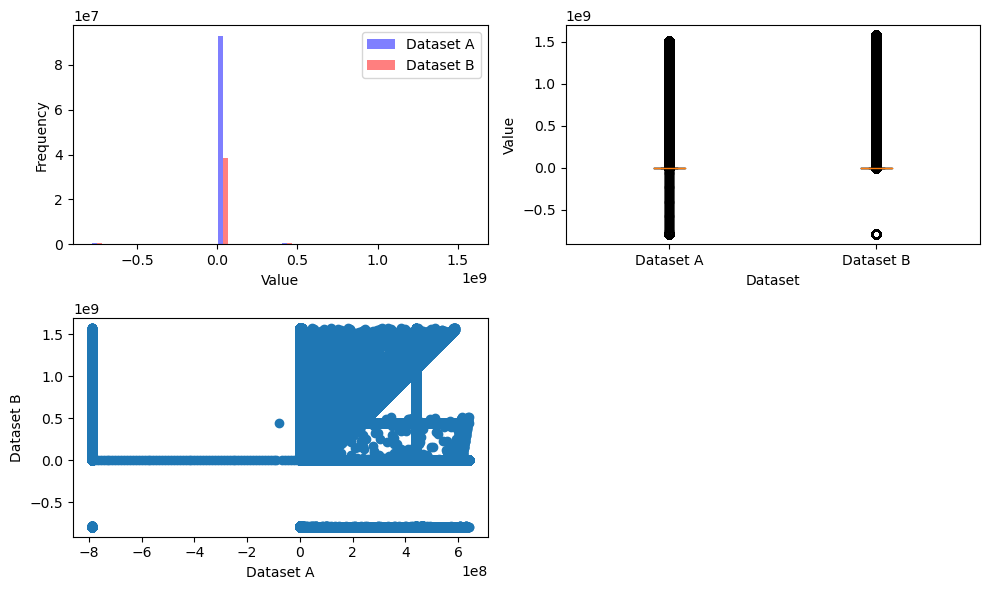

In [51]:
mean_A = np.mean(df1.values.flatten())
mean_B = np.mean(df2.values.flatten())
median_A = np.median(df1.values.flatten())
median_B = np.median(df2.values.flatten())
mode_A = stats.mode(df1.values.flatten()).mode[0]
mode_B = stats.mode(df2.values.flatten()).mode[0]

std_A = np.std(df1.values.flatten())
std_B = np.std(df2.values.flatten())
range_A = np.max(df1.values.flatten()) - np.min(df1.values.flatten())
range_B = np.max(df2.values.flatten()) - np.min(df2.values.flatten())
iqr_A = stats.iqr(df1.values.flatten())
iqr_B = stats.iqr(df2.values.flatten())
var_A = np.var(df1.values.flatten())
var_B = np.var(df2.values.flatten())

num_points = min(len(df1.values.flatten()), len(df2.values.flatten()))
subset_df1 = df1.values.flatten()[:num_points]
subset_df2 = df2.values.flatten()[:num_points]
plt.figure(figsize=(10, 6))
plt.subplot(2, 2, 1)
color = ['blue', 'red']  
label = ['Dataset A', 'Dataset B']
plt.hist([df1.values.flatten(), df2.values.flatten()], bins=30, color=color, alpha=0.5, label=label)
plt.legend()
plt.xlabel('Value')
plt.ylabel('Frequency')
plt.subplot(2, 2, 2)
plt.boxplot([df1.values.flatten(), df2.values.flatten()])
plt.xticks([1, 2], label)
plt.xlabel('Dataset')
plt.ylabel('Value')
plt.subplot(2, 2, 3)
plt.scatter(subset_df1, subset_df2)
plt.xlabel('Dataset A')
plt.ylabel('Dataset B')

t_statistic, p_value = stats.ttest_ind(df1.values.flatten(), df2.values.flatten())
f_statistic, p_value_anova = stats.f_oneway(df1.values.flatten(), df2.values.flatten())

if len(df1.values.flatten()) == len(df2.values.flatten()):
    corr_coef, p_value_corr = stats.pearsonr(df1.values.flatten(), df2.values.flatten())
else:
    corr_coef, p_value_corr = np.nan, np.nan

print("Central Tendency:")
print("Mean (Dataset A):", mean_A)
print("Mean (Dataset B):", mean_B)
print("Median (Dataset A):", median_A)
print("Median (Dataset B):", median_B)
print("Mode (Dataset A):", mode_A)
print("Mode (Dataset B):", mode_B)
print()
print("Variability:")
print("Standard Deviation (Dataset A):", std_A)
print("Standard Deviation (Dataset B):", std_B)
print("Range (Dataset A):", range_A)
print("Range (Dataset B):", range_B)
print("Interquartile Range (Dataset A):", iqr_A)
print("Interquartile Range (Dataset B):", iqr_B)
print("Variance (Dataset A):", var_A)
print("Variance (Dataset B):", var_B)
print()
print("Inferential Statistics:")
print("T-Test (p-value):", p_value)
print("ANOVA (p-value):", p_value_anova)
print()
print("Correlation Analysis:")
print("Pearson's correlation coefficient:", corr_coef)
print("Correlation p-value:", p_value_corr)
plt.tight_layout()
plt.show()

In [52]:
length_df1 = len(df1)
length_df2 = len(df2)
if length_df1 != length_df2:
    min_length = min(length_df1, length_df2)
    df1 = df1[:min_length]
    df2 = df2[:min_length]

In [53]:
print(df1.shape)
print(df2.shape)
print(df1.dtypes)
print(df2.dtypes)

obs1 = np.bincount(df1['label']) 
obs2 = np.bincount(df2['label'])
print(obs1)
print(obs2)

n1 = np.sum(obs1)
n2 = np.sum(obs2)
print(n1)
print(n2)

exp1 = obs1 * n2 / n1
exp2 = obs2 * n1 / n2
chi1, p1 = stats.chisquare(obs1, exp1)
chi2, p2 = stats.chisquare(obs2, exp2)
print(chi1, p1)
print(chi2, p2)

alpha = 0.05  
if p1 < alpha:
    print('Reject null hypothesis for dataset 1')
else:
    print('Cannot reject null hypothesis for dataset 1')
if p2 < alpha:
    print('Reject null hypothesis for dataset 2')
else:
    print('Cannot reject null hypothesis for dataset 2')

(352045, 268)
(352045, 85)
timestamp           int64
control[0]        float64
control[1]        float64
control[2]        float64
control[3]        float64
                   ...   
yaw               float64
thrust_body[0]    float64
thrust_body[1]    float64
thrust_body[2]    float64
label               int64
Length: 268, dtype: object
timestamp              int64
q[0]                 float64
q[1]                 float64
q[2]                 float64
q[3]                 float64
                      ...   
vz_reset_counter     float64
xy_global            float64
z_global             float64
dist_bottom_valid    float64
label                  int64
Length: 85, dtype: object
[344955   7090]
[343405   8640]
352045
352045
0.0 1.0
0.0 1.0
Cannot reject null hypothesis for dataset 1
Cannot reject null hypothesis for dataset 2


In [54]:
print(df1.shape)
print(df2.shape)
print(df1.dtypes)
print(df2.dtypes)

X1 = df1.drop('label', axis=1) 
y1 = df1['label'] 
X2 = df2.drop('label', axis=1) 
y2 = df2['label'] 
X1_train, X1_test, y1_train, y1_test = train_test_split(X1, y1, test_size=0.2, random_state=42) # Dataset 1
X2_train, X2_test, y2_train, y2_test = train_test_split(X2, y2, test_size=0.2, random_state=42) # Dataset 2

model1 = LinearRegression() 
model2 = LinearRegression() 
model1.fit(X1_train, y1_train)
model2.fit(X2_train, y2_train) 

y1_pred = model1.predict(X1_test) 
y2_pred = model2.predict(X2_test) 

mse1 = mean_squared_error(y1_test, y1_pred) 
rmse1 = np.sqrt(mse1) 
r21 = r2_score(y1_test, y1_pred) 
mse2 = mean_squared_error(y2_test, y2_pred) 
rmse2 = np.sqrt(mse2) 
r22 = r2_score(y2_test, y2_pred)

print("Dataset 1:")
print("Mean squared error:", mse1)
print("Root mean squared error:", rmse1)
print("R-squared score:", r21)
print("Dataset 2:")
print("Mean squared error:", mse2)
print("Root mean squared error:", rmse2)
print("R-squared score:", r22)

(352045, 268)
(352045, 85)
timestamp           int64
control[0]        float64
control[1]        float64
control[2]        float64
control[3]        float64
                   ...   
yaw               float64
thrust_body[0]    float64
thrust_body[1]    float64
thrust_body[2]    float64
label               int64
Length: 268, dtype: object
timestamp              int64
q[0]                 float64
q[1]                 float64
q[2]                 float64
q[3]                 float64
                      ...   
vz_reset_counter     float64
xy_global            float64
z_global             float64
dist_bottom_valid    float64
label                  int64
Length: 85, dtype: object
Dataset 1:
Mean squared error: 1.643983746005681e-05
Root mean squared error: 0.0040546069427327735
R-squared score: 0.9991528747912214
Dataset 2:
Mean squared error: 3.994131388181407e-05
Root mean squared error: 0.006319914072344186
R-squared score: 0.9983647987544721


In [55]:
num_samples_df1 = len(df1)
num_samples_df2 = len(df2)
print("Number of samples in Dataset A:", num_samples_df1)
print("Number of samples in Dataset B:", num_samples_df2)

print("Descriptive Statistics:")
print("Dataset A:")
print("Mean:", np.mean(df1.values.flatten()))
print("Median:", np.median(df1.values.flatten()))
print("Standard Deviation:", np.std(df1.values.flatten()))
print("Dataset B:")
print("Mean:", np.mean(df2.values.flatten()))
print("Median:", np.median(df2.values.flatten()))
print("Standard Deviation:", np.std(df2.values.flatten()))

outliers_df1 = np.where(np.abs(stats.zscore(df1.values.flatten())) > 3)
outliers_df2 = np.where(np.abs(stats.zscore(df2.values.flatten())) > 3)
print("Outliers:")
print("Dataset A:", outliers_df1)
print("Dataset B:", outliers_df2)

noise_df1 = df1.values.flatten() - np.mean(df1.values.flatten())
noise_df2 = df2.values.flatten() - np.mean(df2.values.flatten())
print("Noise (Residuals):")
print("Dataset A:")
print("Mean:", np.mean(noise_df1))
print("Standard Deviation:", np.std(noise_df1))
print("Dataset B:")
print("Mean:", np.mean(noise_df2))
print("Standard Deviation:", np.std(noise_df2))

Number of samples in Dataset A: 352045
Number of samples in Dataset B: 352045
Descriptive Statistics:
Dataset A:
Mean: 2956923.0345453834
Median: 0.00036226326
Standard Deviation: 82505976.52350117
Dataset B:
Mean: 8945391.239031646
Median: 0.0231664907941176
Standard Deviation: 141838573.51952136
Outliers:
Dataset A: (array([   15477,    15478,    21910, ..., 94347947, 94347993, 94347994]),)
Dataset B: (array([    4957,     4958,     5042, ..., 29923766, 29923767, 29923768]),)
Noise (Residuals):
Dataset A:
Mean: -4.925295928540464e-10
Standard Deviation: 82505976.52350117
Dataset B:
Mean: 9.46668478863623e-09
Standard Deviation: 141838573.51952136


In [56]:
num_samples_df1 = len(df1)
num_samples_df2 = len(df2)
print("Number of samples in Dataset A:", num_samples_df1)
print("Number of samples in Dataset B:", num_samples_df2)

z_scores_df1 = np.abs(stats.zscore(df1.values.flatten()))
z_scores_df2 = np.abs(stats.zscore(df2.values.flatten()))

outliers_df1 = np.where(z_scores_df1 > 3)[0]
outliers_df2 = np.where(z_scores_df2 > 3)[0]

num_outliers_df1 = len(outliers_df1)
num_outliers_df2 = len(outliers_df2)

print("Number of outliers in Dataset A:", num_outliers_df1)
print("Number of outliers in Dataset B:", num_outliers_df2)

Number of samples in Dataset A: 352045
Number of samples in Dataset B: 352045
Number of outliers in Dataset A: 1185275
Number of outliers in Dataset B: 1114624


Number of samples in Dataset A: 352045
Number of samples in Dataset B: 352045


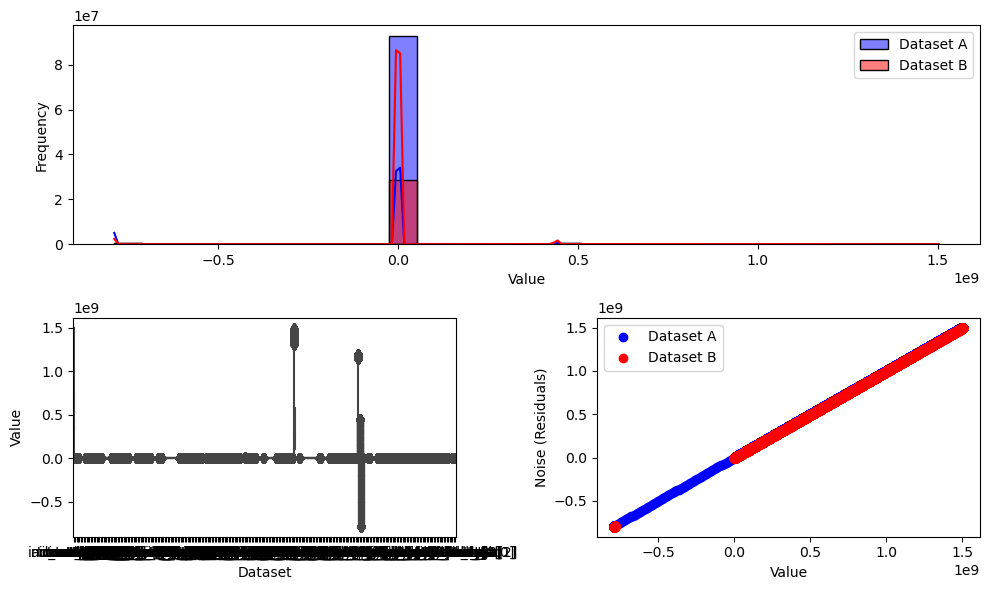

In [57]:
num_samples_df1 = len(df1)
num_samples_df2 = len(df2)
print("Number of samples in Dataset A:", num_samples_df1)
print("Number of samples in Dataset B:", num_samples_df2)

plt.figure(figsize=(10, 6))
plt.subplot(2, 1, 1)
sns.histplot(df1.values.flatten(), bins=30, kde=True, color='blue', label='Dataset A')
sns.histplot(df2.values.flatten(), bins=30, kde=True, color='red', label='Dataset B')
plt.xlabel('Value')
plt.ylabel('Frequency')
plt.legend()

plt.subplot(2, 2, 3)
df_concat = pd.concat([df1.rename(columns={'label': 'Dataset A'}), df2.rename(columns={'label': 'Dataset B'})])
sns.boxplot(data=df_concat)
plt.xlabel('Dataset')
plt.ylabel('Value')

noise_df1 = df1.values.flatten() - np.mean(df1.values.flatten())
noise_df2 = df2.values.flatten() - np.mean(df2.values.flatten())
plt.subplot(2, 2, 4)
plt.scatter(df1.values.flatten(), noise_df1, color='blue', label='Dataset A')
plt.scatter(df2.values.flatten(), noise_df2, color='red', label='Dataset B')
plt.xlabel('Value')
plt.ylabel('Noise (Residuals)')
plt.legend()

plt.tight_layout()
plt.show()

In [61]:
# Import pandas and numpy libraries
import pandas as pd
import numpy as np

# Check if the datasets have the same shape and columns
if df1.shape == df2.shape and df1.columns.equals(df2.columns):
    diff = abs(df1 - df2)
    percent_diff = diff / ((df1 + df2) / 2) * 100
    print(percent_diff)
else:
    print("The datasets have different shapes or columns and cannot be compared.")

The datasets have different shapes or columns and cannot be compared.


# Preprocessing Out-of-Distribution signal data

In [16]:
df=pd.read_csv('PX4-H480-SITL (All).csv')

In [4]:
df['label'].value_counts()

label
malicious    378166
benign       113082
Name: count, dtype: int64

In [5]:
df = df.drop(columns=['timestamp'])

In [6]:
num_features = df.shape[1]
print("The number of features in the dataset is: ", num_features)

The number of features in the dataset is:  267


In [7]:
duplicates = df.duplicated()
print("Number of duplicate rows: ", duplicates.sum())

Number of duplicate rows:  0


In [8]:
df.drop_duplicates(inplace=True)

In [9]:
df['label'].value_counts()

label
malicious    378166
benign       113082
Name: count, dtype: int64

In [15]:
print("Number of rows before removing duplicates: ", df.shape[0])
df.drop_duplicates(inplace=True)
print("Number of rows after removing duplicates: ", df.shape[0])

Number of rows before removing duplicates:  491248
Number of rows after removing duplicates:  491248


In [16]:
duplicates = df.duplicated()
print("Number of duplicate rows: ", duplicates.sum())

Number of duplicate rows:  0


In [17]:
print(df.isnull().sum())

control[0]        0
control[1]        0
control[2]        0
control[3]        0
control[4]        0
                 ..
yaw               0
thrust_body[0]    0
thrust_body[1]    0
thrust_body[2]    0
label             0
Length: 267, dtype: int64


In [18]:
if df.isna().sum().sum() > 0:
    print("There are NaN values in the dataset.")
else:
    print("There are no NaN values in the dataset.")

There are no NaN values in the dataset.


In [19]:
numeric_features = df.dtypes[df.dtypes != 'object'].index
scaler = QuantileTransformer()  
df[numeric_features] = scaler.fit_transform(df[numeric_features])

In [20]:
df[numeric_features]

,control[0],control[1],control[2],control[3],control[4],control[5],control[6],control[7],noutputs,output[0],...,dist_bottom_valid,magnetometer_ga[0],magnetometer_ga[1],magnetometer_ga[2],roll,pitch,yaw,thrust_body[0],thrust_body[1],thrust_body[2]
0,0.138200,0.816104,0.857600,0.0,0.0,0.0,0.0,0.085586,1.0,0.0,...,1.0,0.022523,0.074575,0.604104,0.957860,0.946905,0.000000,0.0,0.0,1.0
1,0.138200,0.816104,0.857600,0.0,0.0,0.0,0.0,0.085586,1.0,0.0,...,1.0,0.022523,0.074575,0.604104,0.957860,0.946905,0.000000,0.0,0.0,1.0
2,0.279602,0.934872,0.015065,0.0,0.0,0.0,0.0,0.085485,1.0,0.0,...,1.0,0.021622,0.074575,0.599199,0.957860,0.946905,0.000000,0.0,0.0,1.0
3,0.734525,0.975177,0.012454,0.0,0.0,0.0,0.0,0.085385,1.0,0.0,...,1.0,0.021221,0.074575,0.598799,0.957860,0.946905,0.000000,0.0,0.0,1.0
4,0.917203,0.987340,0.011669,0.0,0.0,0.0,0.0,0.085285,1.0,0.0,...,1.0,0.019820,0.074575,0.592000,0.957860,0.946905,0.000000,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
491243,0.381363,0.894424,0.012010,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,...,1.0,0.380881,0.159660,0.618118,0.893105,0.710211,0.010009,0.0,0.0,1.0
491244,0.597934,0.876612,0.012011,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,...,1.0,0.380881,0.159660,0.618118,0.893107,0.710179,0.010009,0.0,0.0,1.0
491245,0.691950,0.868986,0.012011,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,...,1.0,0.380881,0.159660,0.618118,0.893627,0.709861,0.010009,0.0,0.0,1.0
491246,0.769378,0.859763,0.012011,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,...,1.0,0.380881,0.159660,0.618118,0.894082,0.709563,0.010009,0.0,0.0,1.0


In [21]:
labelencoder = LabelEncoder()
df.iloc[:, -1] = labelencoder.fit_transform(df.iloc[:, -1])

In [22]:
df

,control[0],control[1],control[2],control[3],control[4],control[5],control[6],control[7],noutputs,output[0],...,magnetometer_ga[0],magnetometer_ga[1],magnetometer_ga[2],roll,pitch,yaw,thrust_body[0],thrust_body[1],thrust_body[2],label
0,0.138200,0.816104,0.857600,0.0,0.0,0.0,0.0,0.085586,1.0,0.0,...,0.022523,0.074575,0.604104,0.957860,0.946905,0.000000,0.0,0.0,1.0,0
1,0.138200,0.816104,0.857600,0.0,0.0,0.0,0.0,0.085586,1.0,0.0,...,0.022523,0.074575,0.604104,0.957860,0.946905,0.000000,0.0,0.0,1.0,0
2,0.279602,0.934872,0.015065,0.0,0.0,0.0,0.0,0.085485,1.0,0.0,...,0.021622,0.074575,0.599199,0.957860,0.946905,0.000000,0.0,0.0,1.0,0
3,0.734525,0.975177,0.012454,0.0,0.0,0.0,0.0,0.085385,1.0,0.0,...,0.021221,0.074575,0.598799,0.957860,0.946905,0.000000,0.0,0.0,1.0,0
4,0.917203,0.987340,0.011669,0.0,0.0,0.0,0.0,0.085285,1.0,0.0,...,0.019820,0.074575,0.592000,0.957860,0.946905,0.000000,0.0,0.0,1.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
491243,0.381363,0.894424,0.012010,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,...,0.380881,0.159660,0.618118,0.893105,0.710211,0.010009,0.0,0.0,1.0,1
491244,0.597934,0.876612,0.012011,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,...,0.380881,0.159660,0.618118,0.893107,0.710179,0.010009,0.0,0.0,1.0,1
491245,0.691950,0.868986,0.012011,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,...,0.380881,0.159660,0.618118,0.893627,0.709861,0.010009,0.0,0.0,1.0,1
491246,0.769378,0.859763,0.012011,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,...,0.380881,0.159660,0.618118,0.894082,0.709563,0.010009,0.0,0.0,1.0,1


In [23]:
df['label'].value_counts()

label
1    378166
0    113082
Name: count, dtype: int64

In [24]:
df.shape

(491248, 267)

In [25]:
df

,control[0],control[1],control[2],control[3],control[4],control[5],control[6],control[7],noutputs,output[0],...,magnetometer_ga[0],magnetometer_ga[1],magnetometer_ga[2],roll,pitch,yaw,thrust_body[0],thrust_body[1],thrust_body[2],label
0,0.138200,0.816104,0.857600,0.0,0.0,0.0,0.0,0.085586,1.0,0.0,...,0.022523,0.074575,0.604104,0.957860,0.946905,0.000000,0.0,0.0,1.0,0
1,0.138200,0.816104,0.857600,0.0,0.0,0.0,0.0,0.085586,1.0,0.0,...,0.022523,0.074575,0.604104,0.957860,0.946905,0.000000,0.0,0.0,1.0,0
2,0.279602,0.934872,0.015065,0.0,0.0,0.0,0.0,0.085485,1.0,0.0,...,0.021622,0.074575,0.599199,0.957860,0.946905,0.000000,0.0,0.0,1.0,0
3,0.734525,0.975177,0.012454,0.0,0.0,0.0,0.0,0.085385,1.0,0.0,...,0.021221,0.074575,0.598799,0.957860,0.946905,0.000000,0.0,0.0,1.0,0
4,0.917203,0.987340,0.011669,0.0,0.0,0.0,0.0,0.085285,1.0,0.0,...,0.019820,0.074575,0.592000,0.957860,0.946905,0.000000,0.0,0.0,1.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
491243,0.381363,0.894424,0.012010,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,...,0.380881,0.159660,0.618118,0.893105,0.710211,0.010009,0.0,0.0,1.0,1
491244,0.597934,0.876612,0.012011,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,...,0.380881,0.159660,0.618118,0.893107,0.710179,0.010009,0.0,0.0,1.0,1
491245,0.691950,0.868986,0.012011,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,...,0.380881,0.159660,0.618118,0.893627,0.709861,0.010009,0.0,0.0,1.0,1
491246,0.769378,0.859763,0.012011,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,...,0.380881,0.159660,0.618118,0.894082,0.709563,0.010009,0.0,0.0,1.0,1


In [26]:
df['label'].value_counts()

label
1    378166
0    113082
Name: count, dtype: int64

In [27]:
df.shape

(491248, 267)

In [28]:
X = df.drop(['label'],axis=1).values
y = df.iloc[:, -1].values.reshape(-1,1)
y=np.ravel(y)
X_train, X_test, y_train, y_test = train_test_split(X,y, train_size = 0.8, test_size = 0.2, random_state = 0,stratify = y)

In [29]:
X = df.drop(['label'], axis=1)
y = df['label']

pca = PCA(n_components=32)
X_pca = pca.fit_transform(X)

pca_df = pd.DataFrame(X_pca, columns=[f'PC{i}' for i in range(1, 33)])
pca_df['label'] = y
pca_df.to_csv('Q.csv', index=False)

In [30]:
df=pd.read_csv('Q.csv')

In [31]:
df

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,...,PC24,PC25,PC26,PC27,PC28,PC29,PC30,PC31,PC32,label
0,1.730372,1.344525,-1.850948,0.824518,-2.560879,-0.384650,-1.796776,-0.899025,-0.185748,0.272990,...,-0.595903,1.202401,0.204731,0.211361,-0.305038,-0.240751,0.406823,-0.310745,0.845683,0
1,1.731505,1.341874,-1.854304,0.827479,-2.564021,-0.388310,-1.789145,-0.894393,-0.180882,0.270956,...,-0.588869,1.206598,0.199477,0.210942,-0.309263,-0.247950,0.396947,-0.311899,0.841612,0
2,1.717987,1.330343,-1.839517,0.855743,-2.567358,-0.385231,-1.787383,-0.929159,-0.038399,0.134306,...,-0.643113,1.231523,0.224198,0.162668,-0.259030,-0.312649,0.280774,-0.377457,0.823015,0
3,1.729589,1.319898,-1.859078,0.864760,-2.121209,-0.874697,-1.783271,-1.011193,0.014286,0.014731,...,-0.675319,1.290069,0.243860,0.135797,-0.284571,-0.365224,0.163781,-0.414298,0.801590,0
4,1.723632,1.315404,-1.861162,0.870798,-2.126237,-0.878496,-1.771017,-1.017765,0.050962,-0.028981,...,-0.679101,1.302219,0.243615,0.122652,-0.291547,-0.386267,0.112814,-0.430643,0.787254,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
491243,-0.324731,2.681715,-0.650027,0.392634,-1.321997,0.921639,-0.978457,0.327623,-0.318107,-0.288291,...,0.063976,0.324662,-0.110849,0.035854,0.948966,-0.024084,-0.487998,-0.603583,-0.122581,1
491244,-0.284626,2.560588,-0.676800,0.403888,-1.255537,0.980297,-0.922085,0.377654,-0.217199,-0.309160,...,0.205707,0.293947,0.010989,0.018478,0.860629,-0.067747,-0.576395,-0.539004,-0.149906,1
491245,-0.303295,2.586735,-0.664530,0.411491,-1.268453,0.971377,-0.945878,0.346841,-0.181245,-0.380107,...,0.165831,0.284397,-0.012357,-0.000933,0.868390,-0.058799,-0.572744,-0.562791,-0.151524,1
491246,-0.315557,2.599347,-0.657053,0.417294,-1.274709,0.968159,-0.962230,0.325425,-0.145982,-0.440845,...,0.138374,0.279143,-0.032338,-0.014722,0.870109,-0.052517,-0.567262,-0.579201,-0.153392,1


In [32]:
df['label'].value_counts()

label
1    378166
0    113082
Name: count, dtype: int64

In [33]:
df=pd.read_csv('Q.csv')

In [34]:
df

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,...,PC24,PC25,PC26,PC27,PC28,PC29,PC30,PC31,PC32,label
0,1.730372,1.344525,-1.850948,0.824518,-2.560879,-0.384650,-1.796776,-0.899025,-0.185748,0.272990,...,-0.595903,1.202401,0.204731,0.211361,-0.305038,-0.240751,0.406823,-0.310745,0.845683,0
1,1.731505,1.341874,-1.854304,0.827479,-2.564021,-0.388310,-1.789145,-0.894393,-0.180882,0.270956,...,-0.588869,1.206598,0.199477,0.210942,-0.309263,-0.247950,0.396947,-0.311899,0.841612,0
2,1.717987,1.330343,-1.839517,0.855743,-2.567358,-0.385231,-1.787383,-0.929159,-0.038399,0.134306,...,-0.643113,1.231523,0.224198,0.162668,-0.259030,-0.312649,0.280774,-0.377457,0.823015,0
3,1.729589,1.319898,-1.859078,0.864760,-2.121209,-0.874697,-1.783271,-1.011193,0.014286,0.014731,...,-0.675319,1.290069,0.243860,0.135797,-0.284571,-0.365224,0.163781,-0.414298,0.801590,0
4,1.723632,1.315404,-1.861162,0.870798,-2.126237,-0.878496,-1.771017,-1.017765,0.050962,-0.028981,...,-0.679101,1.302219,0.243615,0.122652,-0.291547,-0.386267,0.112814,-0.430643,0.787254,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
491243,-0.324731,2.681715,-0.650027,0.392634,-1.321997,0.921639,-0.978457,0.327623,-0.318107,-0.288291,...,0.063976,0.324662,-0.110849,0.035854,0.948966,-0.024084,-0.487998,-0.603583,-0.122581,1
491244,-0.284626,2.560588,-0.676800,0.403888,-1.255537,0.980297,-0.922085,0.377654,-0.217199,-0.309160,...,0.205707,0.293947,0.010989,0.018478,0.860629,-0.067747,-0.576395,-0.539004,-0.149906,1
491245,-0.303295,2.586735,-0.664530,0.411491,-1.268453,0.971377,-0.945878,0.346841,-0.181245,-0.380107,...,0.165831,0.284397,-0.012357,-0.000933,0.868390,-0.058799,-0.572744,-0.562791,-0.151524,1
491246,-0.315557,2.599347,-0.657053,0.417294,-1.274709,0.968159,-0.962230,0.325425,-0.145982,-0.440845,...,0.138374,0.279143,-0.032338,-0.014722,0.870109,-0.052517,-0.567262,-0.579201,-0.153392,1


In [35]:
df['label'].value_counts()

label
1    378166
0    113082
Name: count, dtype: int64

In [36]:
X = df.drop(['label'],axis=1).values
y = df.iloc[:, -1].values.reshape(-1,1)
y=np.ravel(y)

In [37]:
X_train, X_test, y_train, y_test = train_test_split(X,y, train_size = 0.8, test_size = 0.2, random_state = 0,stratify = y)

In [38]:
pd.Series(y_train).value_counts()

1    302532
0     90466
Name: count, dtype: int64

In [39]:
from imblearn.over_sampling import SMOTE

In [40]:
oversample = SMOTE(sampling_strategy="auto")

In [41]:
X_train_oversampled, y_train_oversampled = oversample.fit_resample(X_train, y_train)

Counter({1: 302532, 0: 90466})
Counter({1: 302532, 0: 302532})


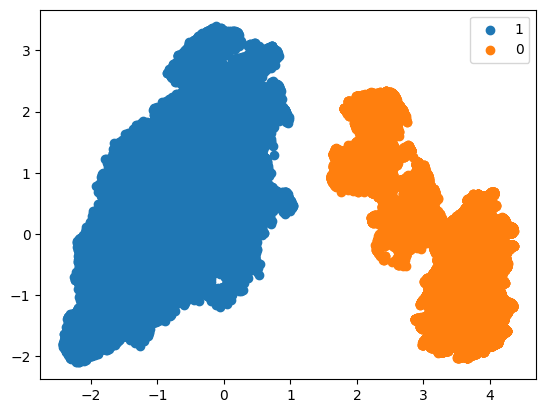

In [42]:
print(Counter(y_train))
print(Counter(y_train_oversampled))
for label, _ in Counter(y_train_oversampled).items():
    row_ix = where(y_train_oversampled == label)[0]
    pyplot.scatter(X_train_oversampled[row_ix, 0], X_train_oversampled[row_ix, 1], label=str(label))
pyplot.legend()
pyplot.show()

In [43]:
# Import pandas
import pandas as pd

# Combine X_train and y_train into one DataFrame
train = pd.concat([pd.DataFrame(X_train_oversampled), pd.Series(y_train_oversampled)], axis=1)

# Combine X_test and y_test into one DataFrame
test = pd.concat([pd.DataFrame(X_test), pd.Series(y_test)], axis=1)

In [ ]:
# Combine train and test data into one DataFrame
df = pd.concat([train, test], axis=0)

In [49]:
X = df.drop(['label'],axis=1).values
y = df.iloc[:, -1].values.reshape(-1,1)
y=np.ravel(y)
X_train, X_test, y_train, y_test = train_test_split(X,y, train_size = 0.8, test_size = 0.2, random_state = 0,stratify = y)

In [50]:
pd.Series(y_train).value_counts()

1    302533
0    260118
Name: count, dtype: int64

In [54]:
df['label'] = df['label'].replace({0: 'Benign', 1: 'GPS Spoofing'})
print(df['label'].value_counts())

label
GPS Spoofing    378166
Benign          325148
Name: count, dtype: int64


In [55]:
numeric_features = df.dtypes[df.dtypes != 'object'].index

In [56]:
df[numeric_features] = df[numeric_features].apply(
    lambda x: (x*255))

In [57]:
df.shape

(703314, 33)

In [58]:
df.label.value_counts()

label
GPS Spoofing    378166
Benign          325148
Name: count, dtype: int64

In [14]:
df0=df[df['label']=='Benign'].drop(['label'],axis=1)
df1=df[df['label']=='GPS Spoofing'].drop(['label'],axis=1)

In [65]:
count=0
ims = []
image_path = "train_Q[SMOTE]/0/"
os.makedirs(image_path)
for i in range(0, len(df0)):  
    count=count+1
    if count<=32*3: 
        im=df0.iloc[i].values
        ims=np.append(ims,im)
    else:
        ims=np.array(ims).reshape(32,32,3)
        array = np.array(ims, dtype=np.uint8)
        new_image = Image.fromarray(array)
        new_image.save(image_path+str(i)+'.png')
        count=0
        ims = []

In [66]:
count=0
ims = []
image_path = "train_Q[SMOTE]/1/"
os.makedirs(image_path)
for i in range(0, len(df1)):  
    count=count+1
    if count<=32*3: 
        im=df1.iloc[i].values
        ims=np.append(ims,im)
    else:
        ims=np.array(ims).reshape(32,32,3)
        array = np.array(ims, dtype=np.uint8)
        new_image = Image.fromarray(array)
        new_image.save(image_path+str(i)+'.png')
        count=0
        ims = []

In [15]:
data_dir = pathlib.Path('train_Q[SMOTE]')
data_dir

PosixPath('train_Q[SMOTE]')

In [16]:
batch_size = 32
img_height = 224
img_width = 224

import tensorflow as tf
from tensorflow.keras.preprocessing import image_dataset_from_directory

# Load the dataset from the directory
full_ds = image_dataset_from_directory(
    data_dir,
    seed=123,
    image_size=(img_height, img_width),
    batch_size=batch_size,
    shuffle=True,  # Shuffle the dataset
)

# Calculate the number of batches for train, validation, and test
num_batches = len(full_ds)
num_train_batches = 0  # Number of batches for training
num_val_batches = 50  # Number of batches for validation
num_test_batches = 50   # Number of batches for testing

# Split the dataset manually
train_ds = full_ds.take(num_train_batches)
val_ds = full_ds.skip(num_train_batches).take(num_val_batches)
test_ds = full_ds.skip(num_train_batches + num_val_batches).take(num_test_batches)

class_names = full_ds.class_names
num_classes = len(class_names)

print("Number of train batches:", num_train_batches)
print("Number of validation batches:", num_val_batches)
print("Number of test batches:", num_test_batches)

Found 7250 files belonging to 2 classes.


2024-02-08 21:39:20.031441: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1886] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 30955 MB memory:  -> device: 0, name: Tesla V100-SXM2-32GB, pci bus id: 0000:61:00.0, compute capability: 7.0


Number of train batches: 0
Number of validation batches: 50
Number of test batches: 50


In [17]:
import tensorflow as tf
from tensorflow.keras.preprocessing import image_dataset_from_directory

# Load the dataset from the directory
full_ds = image_dataset_from_directory(
    data_dir,
    seed=123,
    image_size=(img_height, img_width),
    batch_size=batch_size,
)

Found 7250 files belonging to 2 classes.


# Testing models on Out-of-Distribution signal data (Anomaly Detection)

## ResNet 50

In [39]:
model_ResNet50 = tf.keras.models.load_model('ResNet50+TL.h5')

2024-02-08 18:24:50.700476: I tensorflow/compiler/xla/stream_executor/cuda/cuda_dnn.cc:442] Loaded cuDNN version 8904


Predictions:
 [1 0 0 ... 0 1 1]
Label:
 [1 0 0 ... 0 0 1]


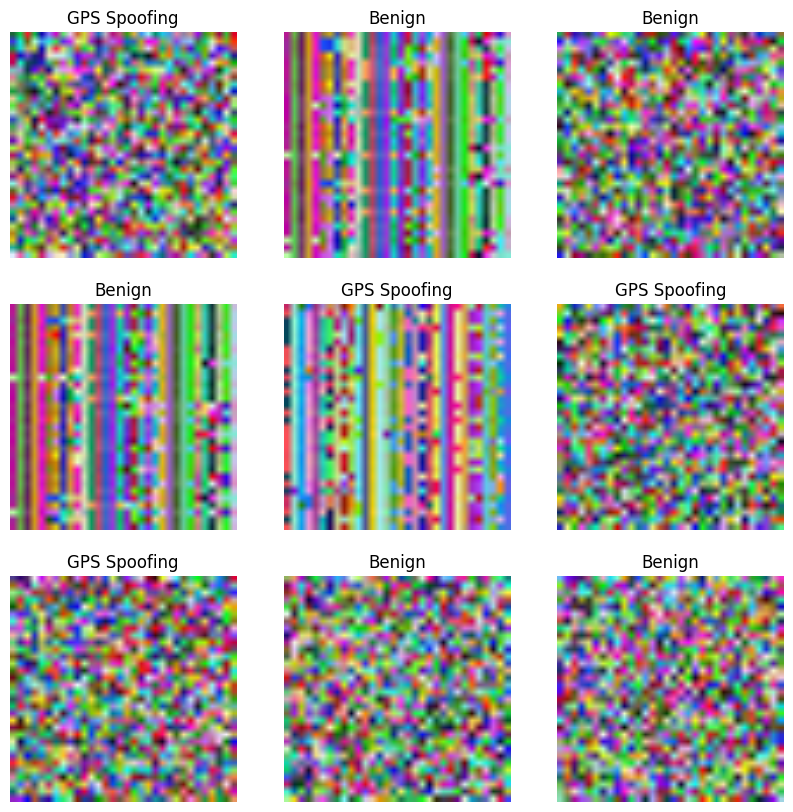

In [40]:
class_names_s = ['Benign', 'GPS Spoofing']
all_predictions_ResNet50 = []
all_label_ResNet50 = []

for image_batch, label_batch in test_ds.as_numpy_iterator():
    predictions = model_ResNet50.predict_on_batch(image_batch).flatten()
    predictions = tf.nn.sigmoid(predictions)
    predictions = tf.where(predictions < 0.5, 0, 1)
    all_predictions_ResNet50.append(predictions)
    all_label_ResNet50.append(label_batch)
    
all_predictions_ResNet50 = np.concatenate(all_predictions_ResNet50)
all_label_ResNet50 = np.concatenate(all_label_ResNet50)
print('Predictions:\n', all_predictions_ResNet50)
print('Label:\n', all_label_ResNet50)

report_ResNet50 = classification_report(all_label_ResNet50 , all_predictions_ResNet50, target_names=class_names_s)
plt.figure(figsize=(10, 10))
for i in range(9):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(image_batch[i].astype("uint8"))
    plt.title(class_names_s[all_predictions_ResNet50[i]])
    plt.axis("off")

In [41]:
cm=confusion_matrix(all_label_ResNet50 ,all_predictions_ResNet50)
TP = np.sum((all_predictions_ResNet50 == 1) & (all_label_ResNet50 == 1))
FP = np.sum((all_predictions_ResNet50 == 1) & (all_label_ResNet50 == 0))
FN = np.sum((all_predictions_ResNet50 == 0) & (all_label_ResNet50 == 1))
TN = cm[0, 0]
DA = (TP + TN) / len(all_label_ResNet50)
DP = TP / (TP + FP)
DS = TP / (TP + FN)
DF = 2 * (DP * DS) / (DP + DS)
DE = 1 - DA
FR = FP / (FP + TN)
total_predictions = TP + FP + TN + FN
prediction_overhead = (TP + FP) / total_predictions
TN, FP, FN, TP = confusion_matrix(all_label_ResNet50 , all_predictions_ResNet50).ravel()
specificity = TN / (TN + FP)

Test_ds (ResNet50)
                  
              precision    recall  f1-score   support

      Benign       0.99      0.56      0.71       885
GPS Spoofing       0.64      0.99      0.78       715

    accuracy                           0.75      1600
   macro avg       0.82      0.78      0.75      1600
weighted avg       0.84      0.75      0.74      1600

                  
1) Accuracy: 0.7525
                  
2) Precision: 0.836731426637796
                  
3) Recall: 0.7525
                  
4) Average F1-score: 0.7441677651846226
                  
5) F1-score for each type of attack: [0.71345876 0.78217822]
                  
6) Average ROC AUC: 0.7757338706491249
                  
7) Average PR AUC: 0.6434994357410496
                  
8) Balanced Accuracy: 0.7757338706491248
                  
9) Hinge: 0.800625
                  
10) Matthews Correlation Coefficient: 0.5924869903180646
                  
11) Jaccard Score: 0.6422764227642277
                  
12) 

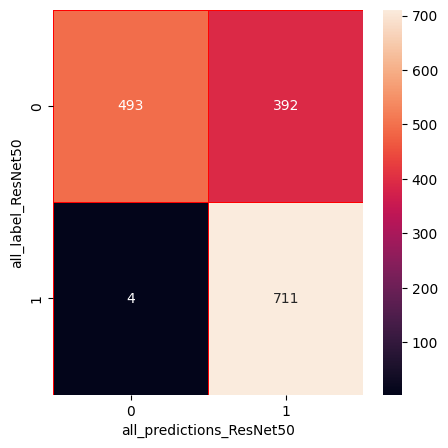

In [42]:
print("Test_ds (ResNet50)")
print("                  ")
print(report_ResNet50)
print("                  ")

print("1) Accuracy: "+ str(accuracy_score(all_label_ResNet50 , all_predictions_ResNet50)))
print("                  ")
print("2) Precision: "+ str(precision_score(all_label_ResNet50 , all_predictions_ResNet50, average='weighted')))
print("                  ")
print("3) Recall: "+ str(recall_score(all_label_ResNet50 , all_predictions_ResNet50, average='weighted')))
print("                  ")
print("4) Average F1-score: "+ str(f1_score(all_label_ResNet50 , all_predictions_ResNet50, average='weighted')))
print("                  ")
print("5) F1-score for each type of attack: "+ str(f1_score(all_label_ResNet50 , all_predictions_ResNet50, average=None)))
print("                  ")
print("6) Average ROC AUC: " + str(roc_auc_score(all_label_ResNet50 , all_predictions_ResNet50, average='weighted')))
print("                  ")
print("7) Average PR AUC: " + str(average_precision_score(all_label_ResNet50 , all_predictions_ResNet50, average='weighted')))
print("                  ")
print("8) Balanced Accuracy: "+ str(balanced_accuracy_score(all_label_ResNet50 , all_predictions_ResNet50)))
print("                  ")
print("9) Hinge: "+ str(hinge_loss(all_label_ResNet50 , all_predictions_ResNet50)))
print("                  ")
print("10) Matthews Correlation Coefficient: "+ str(matthews_corrcoef(all_label_ResNet50 , all_predictions_ResNet50)))
print("                  ")
print("11) Jaccard Score: "+ str(jaccard_score(all_label_ResNet50 , all_predictions_ResNet50)))
print("                  ")
print("12) Log Loss: "+ str(log_loss(all_label_ResNet50 , all_predictions_ResNet50)))
print("                  ")
print("13) Zero-One Loss "+ str(zero_one_loss(all_label_ResNet50 , all_predictions_ResNet50)))
print("                  ")
print("14) Prediction Overhead : {:.4f}".format(prediction_overhead))
print("                  ")
print("15) Specificity: : {:.4f}".format(specificity))

cm=confusion_matrix(all_label_ResNet50 ,all_predictions_ResNet50)
f,ax=plt.subplots(figsize=(5,5))
sns.heatmap(cm,annot=True,linewidth=0.5,linecolor="red",fmt=".0f",ax=ax)
plt.xlabel("all_predictions_ResNet50")
plt.ylabel("all_label_ResNet50")
plt.show()

In [43]:
loss_test_ResNet50, accuracy_test_ResNet50 = model_ResNet50.evaluate(test_ds) 
print("Test loss: {:.4f}".format(loss_test_ResNet50))
print("Test accuracy: {:.4f}".format(accuracy_test_ResNet50))

50/50 [==============================] - 3s 35ms/step - loss: 0.6642 - accuracy: 0.7900
Test loss: 0.6642
Test accuracy: 0.7900


### Val_ds

Predictions:
 [1 1 1 ... 1 1 1]
Label:
 [1 1 1 ... 1 1 1]


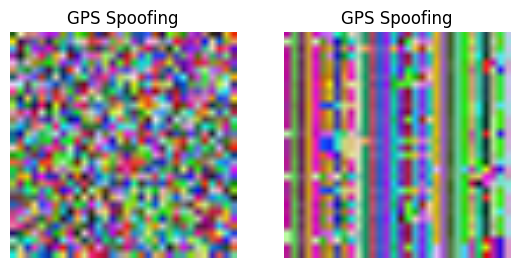

In [44]:
class_names_s = ['Benign', 'GPS Spoofing']

all_predictions_ResNet50 = []
all_label_ResNet50 = []
for image_batch, label_batch in val_ds.as_numpy_iterator():
    predictions = model_ResNet50.predict_on_batch(image_batch).flatten()
    predictions = tf.nn.sigmoid(predictions)
    predictions = tf.where(predictions < 0.5, 0, 1)
    all_predictions_ResNet50.append(predictions)
    all_label_ResNet50.append(label_batch)

all_predictions_ResNet50 = np.concatenate(all_predictions_ResNet50)
all_label_ResNet50 = np.concatenate(all_label_ResNet50)
print('Predictions:\n', all_predictions_ResNet50)
print('Label:\n', all_label_ResNet50)

report_ResNet50 = classification_report(all_label_ResNet50 , all_predictions_ResNet50, target_names=class_names_s)
plt.figure(figsize=(10, 10))
for i in range(2):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(image_batch[i].astype("uint8"))
    plt.title(class_names_s[all_predictions_ResNet50[i]])
    plt.axis("off")

val_ds (ResNet50)
                  
              precision    recall  f1-score   support

      Benign       0.99      0.60      0.75       883
GPS Spoofing       0.67      0.99      0.80       717

    accuracy                           0.78      1600
   macro avg       0.83      0.80      0.77      1600
weighted avg       0.85      0.78      0.77      1600

                  
1) Accuracy: 0.7775
                  
2) Precision: 0.8460303359626775
                  
3) Recall: 0.7775
                  
4) Average F1-score: 0.7721113856021162
                  
5) F1-score for each type of attack: [0.74964838 0.79977503]
                  
6) Average ROC AUC: 0.7976279041116013
                  
7) Average PR AUC: 0.6682648060367775
                  
8) Balanced Accuracy: 0.7976279041116012
                  
9) Hinge: 0.774375
                  
10) Matthews Correlation Coefficient: 0.6263131018621424
                  
11) Jaccard Score: 0.6663542642924086
                  
12) 

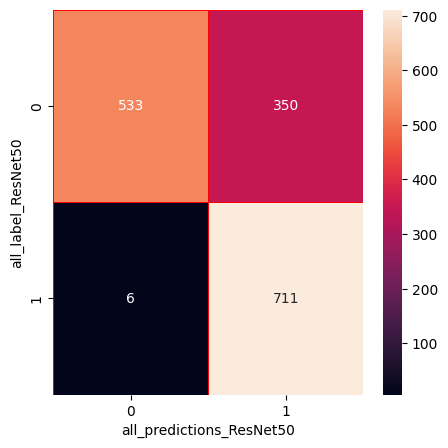

In [45]:
print("val_ds (ResNet50)")
print("                  ")
print(report_ResNet50)
print("                  ")

print("1) Accuracy: "+ str(accuracy_score(all_label_ResNet50 , all_predictions_ResNet50)))
print("                  ")
print("2) Precision: "+ str(precision_score(all_label_ResNet50 , all_predictions_ResNet50, average='weighted')))
print("                  ")
print("3) Recall: "+ str(recall_score(all_label_ResNet50 , all_predictions_ResNet50, average='weighted')))
print("                  ")
print("4) Average F1-score: "+ str(f1_score(all_label_ResNet50 , all_predictions_ResNet50, average='weighted')))
print("                  ")
print("5) F1-score for each type of attack: "+ str(f1_score(all_label_ResNet50 , all_predictions_ResNet50, average=None)))
print("                  ")
print("6) Average ROC AUC: " + str(roc_auc_score(all_label_ResNet50 , all_predictions_ResNet50, average='weighted')))
print("                  ")
print("7) Average PR AUC: " + str(average_precision_score(all_label_ResNet50 , all_predictions_ResNet50, average='weighted')))
print("                  ")
print("8) Balanced Accuracy: "+ str(balanced_accuracy_score(all_label_ResNet50 , all_predictions_ResNet50)))
print("                  ")
print("9) Hinge: "+ str(hinge_loss(all_label_ResNet50 , all_predictions_ResNet50)))
print("                  ")
print("10) Matthews Correlation Coefficient: "+ str(matthews_corrcoef(all_label_ResNet50 , all_predictions_ResNet50)))
print("                  ")
print("11) Jaccard Score: "+ str(jaccard_score(all_label_ResNet50 , all_predictions_ResNet50)))
print("                  ")
print("12) Log Loss: "+ str(log_loss(all_label_ResNet50 , all_predictions_ResNet50)))
print("                  ")
print("13) Zero-One Loss "+ str(zero_one_loss(all_label_ResNet50 , all_predictions_ResNet50)))
print("                  ")
print("14) Prediction Overhead : {:.4f}".format(prediction_overhead))
print("                  ")
print("15) Specificity: : {:.4f}".format(specificity))

cm=confusion_matrix(all_label_ResNet50 ,all_predictions_ResNet50)
f,ax=plt.subplots(figsize=(5,5))
sns.heatmap(cm,annot=True,linewidth=0.5,linecolor="red",fmt=".0f",ax=ax)
plt.xlabel("all_predictions_ResNet50")
plt.ylabel("all_label_ResNet50")
plt.show()

In [46]:
loss_val_ResNet50, accuracy_val_ResNet50 = model_ResNet50.evaluate(val_ds)
print("Validation loss: {:.4f}".format(loss_val_ResNet50))
print("Validation accuracy: {:.4f}".format(accuracy_val_ResNet50))

50/50 [==============================] - 2s 35ms/step - loss: 0.5819 - accuracy: 0.8131
Validation loss: 0.5819
Validation accuracy: 0.8131


## VGG19 

In [72]:
model_VGG19 = tf.keras.models.load_model('VGG19+TL.h5')

Predictions:
 [1 0 0 ... 0 0 0]
Labels:
 [1 0 0 ... 0 0 0]


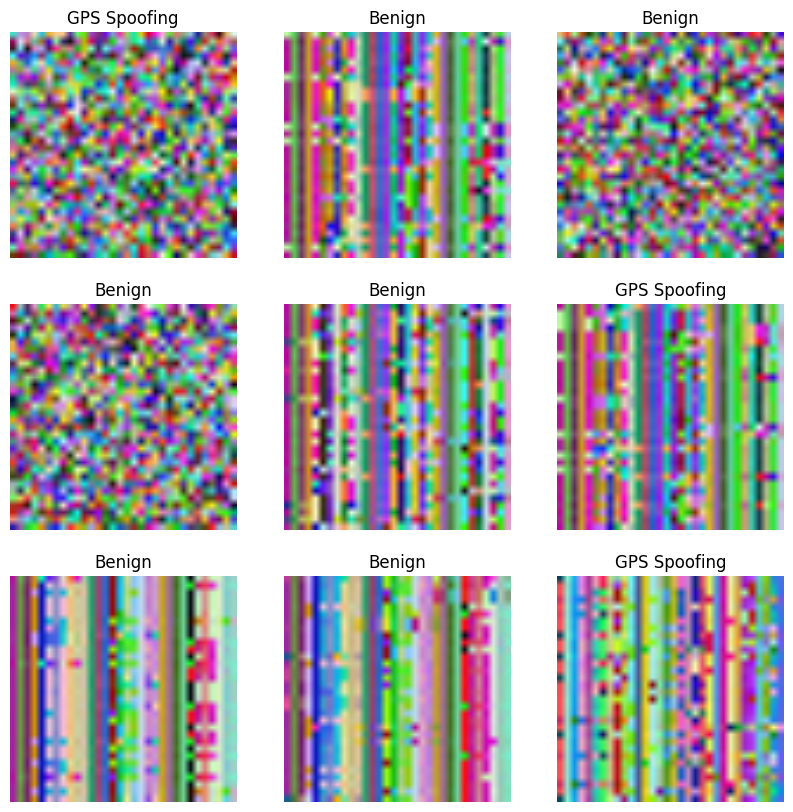

In [73]:
class_names_s = ['Benign', 'GPS Spoofing']
all_predictions_VGG19 = []
all_labels_VGG19 = []

for image_batch, label_batch in test_ds.as_numpy_iterator():
    predictions = model_VGG19.predict_on_batch(image_batch).flatten()
    predictions = tf.nn.sigmoid(predictions)
    predictions = tf.where(predictions < 0.5, 0, 1)
    all_predictions_VGG19.append(predictions)
    all_labels_VGG19.append(label_batch)
    
all_predictions_VGG19 = np.concatenate(all_predictions_VGG19)
all_labels_VGG19 = np.concatenate(all_labels_VGG19)
print('Predictions:\n', all_predictions_VGG19)
print('Labels:\n', all_labels_VGG19)

report_VGG19 = classification_report(all_labels_VGG19, all_predictions_VGG19, target_names=class_names_s)
plt.figure(figsize=(10, 10))
for i in range(9):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(image_batch[i].astype("uint8"))
    plt.title(class_names_s[all_predictions_VGG19[i]])
    plt.axis("off")

In [74]:
cm=confusion_matrix(all_labels_VGG19 ,all_predictions_VGG19)
TP = np.sum((all_predictions_VGG19 == 1) & (all_labels_VGG19 == 1))
FP = np.sum((all_predictions_VGG19 == 1) & (all_labels_VGG19 == 0))
FN = np.sum((all_predictions_VGG19 == 0) & (all_labels_VGG19 == 1))
TN = cm[0, 0]
DA = (TP + TN) / len(all_labels_VGG19)
DP = TP / (TP + FP)
DS = TP / (TP + FN)
DF = 2 * (DP * DS) / (DP + DS)
DE = 1 - DA
FR = FP / (FP + TN)
total_predictions = TP + FP + TN + FN
prediction_overhead = (TP + FP) / total_predictions
TN, FP, FN, TP = confusion_matrix(all_labels_VGG19, all_predictions_VGG19).ravel()
specificity = TN / (TN + FP)

test_ds (VGG19)
                  
              precision    recall  f1-score   support

      Benign       0.98      1.00      0.99       868
GPS Spoofing       1.00      0.98      0.99       732

    accuracy                           0.99      1600
   macro avg       0.99      0.99      0.99      1600
weighted avg       0.99      0.99      0.99      1600

                  
1) Accuracy: 0.990625
                  
2) Precision: 0.9907428142252056
                  
3) Recall: 0.990625
                  
4) Average F1-score: 0.9906178444392169
                  
5) F1-score for each type of attack: [0.99142367 0.9896623 ]
                  
6) Average ROC AUC: 0.989861121603586
                  
7) Average PR AUC: 0.9882600967494319
                  
8) Balanced Accuracy: 0.989861121603586
                  
9) Hinge: 0.551875
                  
10) Matthews Correlation Coefficient: 0.981219051449836
                  
11) Jaccard Score: 0.9795361527967258
                  
12) L

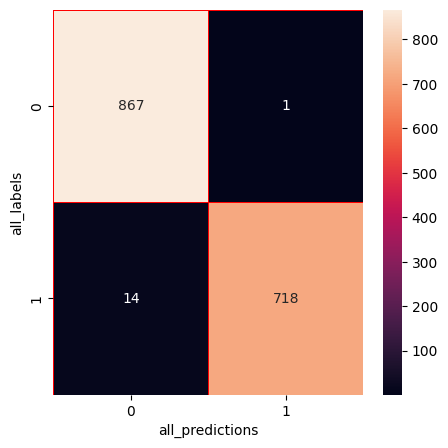

In [75]:
print("test_ds (VGG19)")
print("                  ")
print(report_VGG19)
print("                  ")

print("1) Accuracy: "+ str(accuracy_score(all_labels_VGG19 , all_predictions_VGG19)))
print("                  ")
print("2) Precision: "+ str(precision_score(all_labels_VGG19 , all_predictions_VGG19, average='weighted')))
print("                  ")
print("3) Recall: "+ str(recall_score(all_labels_VGG19 , all_predictions_VGG19, average='weighted')))
print("                  ")
print("4) Average F1-score: "+ str(f1_score(all_labels_VGG19 , all_predictions_VGG19, average='weighted')))
print("                  ")
print("5) F1-score for each type of attack: "+ str(f1_score(all_labels_VGG19 , all_predictions_VGG19, average=None)))
print("                  ")
print("6) Average ROC AUC: " + str(roc_auc_score(all_labels_VGG19 , all_predictions_VGG19, average='weighted')))
print("                  ")
print("7) Average PR AUC: " + str(average_precision_score(all_labels_VGG19 , all_predictions_VGG19, average='weighted')))
print("                  ")
print("8) Balanced Accuracy: "+ str(balanced_accuracy_score(all_labels_VGG19 , all_predictions_VGG19)))
print("                  ")
print("9) Hinge: "+ str(hinge_loss(all_labels_VGG19 , all_predictions_VGG19)))
print("                  ")
print("10) Matthews Correlation Coefficient: "+ str(matthews_corrcoef(all_labels_VGG19 , all_predictions_VGG19)))
print("                  ")
print("11) Jaccard Score: "+ str(jaccard_score(all_labels_VGG19 , all_predictions_VGG19)))
print("                  ")
print("12) Log Loss: "+ str(log_loss(all_labels_VGG19 , all_predictions_VGG19)))
print("                  ")
print("13) Zero-One Loss "+ str(zero_one_loss(all_labels_VGG19 , all_predictions_VGG19)))
print("  ")
print("14) Prediction Overhead : {:.4f}".format(prediction_overhead))
print("                  ")
print("15) Specificity: : {:.4f}".format(specificity))

cm=confusion_matrix(all_labels_VGG19 ,all_predictions_VGG19)
f,ax=plt.subplots(figsize=(5,5))
sns.heatmap(cm,annot=True,linewidth=0.5,linecolor="red",fmt=".0f",ax=ax)
plt.xlabel("all_predictions")
plt.ylabel("all_labels")
plt.show()

In [76]:
loss_test_VGG19, accuracy_test_VGG19 = model_VGG19.evaluate(test_ds)
print("test loss_VGG19: {:.4f}".format(loss_test_VGG19))
print("test accuracy_VGG19: {:.4f}".format(accuracy_test_VGG19))

50/50 [==============================] - 3s 47ms/step - loss: 0.0536 - accuracy: 0.9912
test loss_VGG19: 0.0536
test accuracy_VGG19: 0.9912


### Val_ds (VGG19)

Predictions:
 [0 1 1 ... 1 1 1]
Labels:
 [0 1 1 ... 1 1 1]


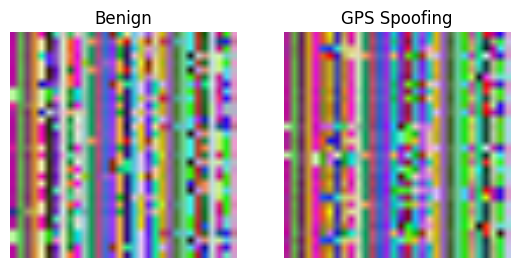

In [77]:
class_names_s = ['Benign', 'GPS Spoofing']
all_predictions_VGG19 = []
all_labels_VGG19 = []

for image_batch, label_batch in val_ds.as_numpy_iterator():
    predictions = model_VGG19.predict_on_batch(image_batch).flatten()
    predictions = tf.nn.sigmoid(predictions)
    predictions = tf.where(predictions < 0.5, 0, 1)
    all_predictions_VGG19.append(predictions)
    all_labels_VGG19.append(label_batch)
    
all_predictions_VGG19 = np.concatenate(all_predictions_VGG19)
all_labels_VGG19 = np.concatenate(all_labels_VGG19)
print('Predictions:\n', all_predictions_VGG19)
print('Labels:\n', all_labels_VGG19)
report_VGG19 = classification_report(all_labels_VGG19 , all_predictions_VGG19, target_names=class_names_s)

plt.figure(figsize=(10, 10))
for i in range(2):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(image_batch[i].astype("uint8"))
    plt.title(class_names_s[all_predictions_VGG19[i]])
    plt.axis("off")

val_ds (VGG19)
                  
              precision    recall  f1-score   support

      Benign       0.98      1.00      0.99       888
GPS Spoofing       1.00      0.97      0.98       712

    accuracy                           0.99      1600
   macro avg       0.99      0.98      0.99      1600
weighted avg       0.99      0.99      0.99      1600

                  
1) Accuracy: 0.98625
                  
2) Precision: 0.9865210333324845
                  
3) Recall: 0.98625
                  
4) Average F1-score: 0.98622862454711
                  
5) F1-score for each type of attack: [0.98775056 0.98433048]
                  
6) Average ROC AUC: 0.9846897459257009
                  
7) Average PR AUC: 0.9822281532116646
                  
8) Balanced Accuracy: 0.9846897459257009
                  
9) Hinge: 0.56875
                  
10) Matthews Correlation Coefficient: 0.9723986243768394
                  
11) Jaccard Score: 0.9691444600280504
                  
12) Log 

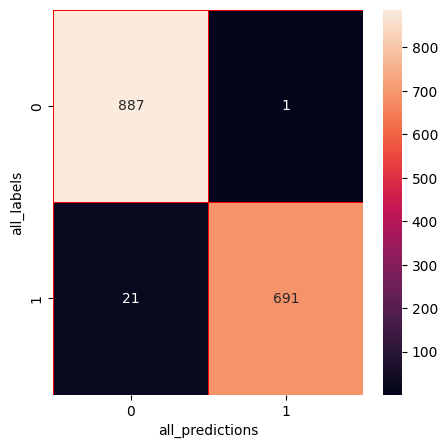

In [78]:
print("val_ds (VGG19)")
print("                  ")
print(report_VGG19)
print("                  ")

print("1) Accuracy: "+ str(accuracy_score(all_labels_VGG19 , all_predictions_VGG19)))
print("                  ")
print("2) Precision: "+ str(precision_score(all_labels_VGG19 , all_predictions_VGG19, average='weighted')))
print("                  ")
print("3) Recall: "+ str(recall_score(all_labels_VGG19 , all_predictions_VGG19, average='weighted')))
print("                  ")
print("4) Average F1-score: "+ str(f1_score(all_labels_VGG19 , all_predictions_VGG19, average='weighted')))
print("                  ")
print("5) F1-score for each type of attack: "+ str(f1_score(all_labels_VGG19 , all_predictions_VGG19, average=None)))
print("                  ")
print("6) Average ROC AUC: " + str(roc_auc_score(all_labels_VGG19, all_predictions_VGG19, average='weighted')))
print("                  ")
print("7) Average PR AUC: " + str(average_precision_score(all_labels_VGG19, all_predictions_VGG19, average='weighted')))
print("                  ")
print("8) Balanced Accuracy: "+ str(balanced_accuracy_score(all_labels_VGG19, all_predictions_VGG19)))
print("                  ")
print("9) Hinge: "+ str(hinge_loss(all_labels_VGG19, all_predictions_VGG19)))
print("                  ")
print("10) Matthews Correlation Coefficient: "+ str(matthews_corrcoef(all_labels_VGG19, all_predictions_VGG19)))
print("                  ")
print("11) Jaccard Score: "+ str(jaccard_score(all_labels_VGG19, all_predictions_VGG19)))
print("                  ")
print("12) Log Loss: "+ str(log_loss(all_labels_VGG19, all_predictions_VGG19)))
print("                  ")
print("13) Zero-One Loss "+ str(zero_one_loss(all_labels_VGG19, all_predictions_VGG19)))
print("  ")
print("14) Prediction Overhead : {:.4f}".format(prediction_overhead))
print("                  ")
print("15) Specificity: : {:.4f}".format(specificity))

cm=confusion_matrix(all_labels_VGG19 ,all_predictions_VGG19)
f,ax=plt.subplots(figsize=(5,5))
sns.heatmap(cm,annot=True,linewidth=0.5,linecolor="red",fmt=".0f",ax=ax)
plt.xlabel("all_predictions")
plt.ylabel("all_labels")
plt.show()

In [79]:
loss_val_VGG19, accuracy_val_VGG19 = model_VGG19.evaluate(test_ds)
print("test loss_VGG19: {:.4f}".format(loss_val_VGG19))
print("test accuracy_VGG19: {:.4f}".format(accuracy_val_VGG19))

50/50 [==============================] - 2s 47ms/step - loss: 0.0578 - accuracy: 0.9906
test loss_VGG19: 0.0578
test accuracy_VGG19: 0.9906


## VGG19 

In [84]:
model_VGG19 = tf.keras.models.load_model('VGG19+TL.h5')

Predictions:
 [1 0 1 ... 1 1 1]
Labels:
 [1 0 1 ... 1 1 1]


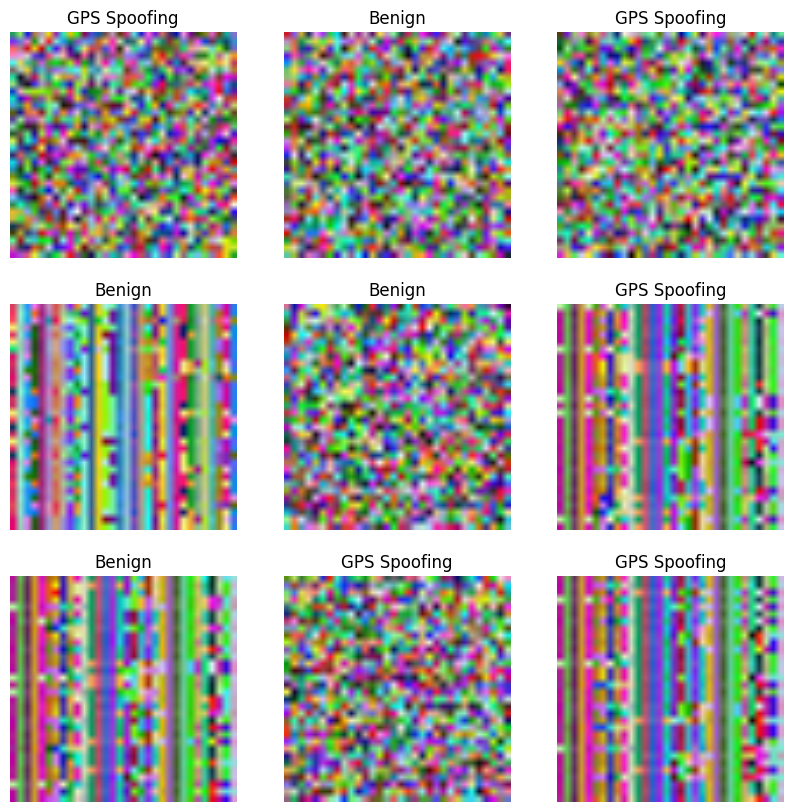

In [85]:
class_names_s = ['Benign', 'GPS Spoofing']
all_predictions_VGG19 = []
all_labels_VGG19 = []

for image_batch, label_batch in test_ds.as_numpy_iterator():
    predictions = model_VGG19.predict_on_batch(image_batch).flatten()
    predictions = tf.nn.sigmoid(predictions)
    predictions = tf.where(predictions < 0.5, 0, 1)
    all_predictions_VGG19.append(predictions)
    all_labels_VGG19.append(label_batch)
    
all_predictions_VGG19 = np.concatenate(all_predictions_VGG19)
all_labels_VGG19 = np.concatenate(all_labels_VGG19)
print('Predictions:\n', all_predictions_VGG19)
print('Labels:\n', all_labels_VGG19)

report_VGG19 = classification_report(all_labels_VGG19, all_predictions_VGG19, target_names=class_names_s)
plt.figure(figsize=(10, 10))
for i in range(9):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(image_batch[i].astype("uint8"))
    plt.title(class_names_s[all_predictions_VGG19[i]])
    plt.axis("off")

In [86]:
cm=confusion_matrix(all_labels_VGG19 ,all_predictions_VGG19)
TP = np.sum((all_predictions_VGG19 == 1) & (all_labels_VGG19 == 1))
FP = np.sum((all_predictions_VGG19 == 1) & (all_labels_VGG19 == 0))
FN = np.sum((all_predictions_VGG19 == 0) & (all_labels_VGG19 == 1))
TN = cm[0, 0]
DA = (TP + TN) / len(all_labels_VGG19)
DP = TP / (TP + FP)
DS = TP / (TP + FN)
DF = 2 * (DP * DS) / (DP + DS)
DE = 1 - DA
FR = FP / (FP + TN)
total_predictions = TP + FP + TN + FN
prediction_overhead = (TP + FP) / total_predictions
TN, FP, FN, TP = confusion_matrix(all_labels_VGG19, all_predictions_VGG19).ravel()
specificity = TN / (TN + FP)

test_ds (VGG19)
                  
              precision    recall  f1-score   support

      Benign       0.98      1.00      0.99       883
GPS Spoofing       1.00      0.98      0.99       717

    accuracy                           0.99      1600
   macro avg       0.99      0.99      0.99      1600
weighted avg       0.99      0.99      0.99      1600

                  
1) Accuracy: 0.99125
                  
2) Precision: 0.9913865663322184
                  
3) Recall: 0.99125
                  
4) Average F1-score: 0.9912412763095426
                  
5) F1-score for each type of attack: [0.99213483 0.99014085]
                  
6) Average ROC AUC: 0.9902370990237099
                  
7) Average PR AUC: 0.9892241980474198
                  
8) Balanced Accuracy: 0.9902370990237099
                  
9) Hinge: 0.560625
                  
10) Matthews Correlation Coefficient: 0.9824313552379091
                  
11) Jaccard Score: 0.9804741980474198
                  
12) 

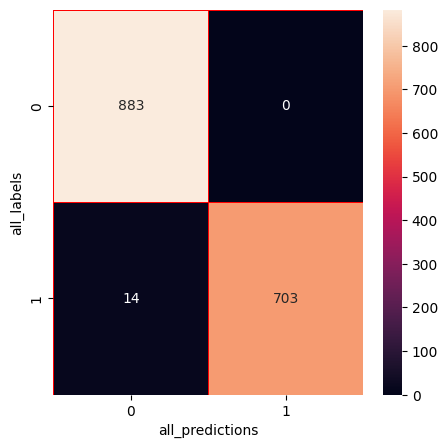

In [87]:
print("test_ds (VGG19)")
print("                  ")
print(report_VGG19)
print("                  ")

print("1) Accuracy: "+ str(accuracy_score(all_labels_VGG19 , all_predictions_VGG19)))
print("                  ")
print("2) Precision: "+ str(precision_score(all_labels_VGG19 , all_predictions_VGG19, average='weighted')))
print("                  ")
print("3) Recall: "+ str(recall_score(all_labels_VGG19 , all_predictions_VGG19, average='weighted')))
print("                  ")
print("4) Average F1-score: "+ str(f1_score(all_labels_VGG19 , all_predictions_VGG19, average='weighted')))
print("                  ")
print("5) F1-score for each type of attack: "+ str(f1_score(all_labels_VGG19 , all_predictions_VGG19, average=None)))
print("                  ")
print("6) Average ROC AUC: " + str(roc_auc_score(all_labels_VGG19 , all_predictions_VGG19, average='weighted')))
print("                  ")
print("7) Average PR AUC: " + str(average_precision_score(all_labels_VGG19 , all_predictions_VGG19, average='weighted')))
print("                  ")
print("8) Balanced Accuracy: "+ str(balanced_accuracy_score(all_labels_VGG19 , all_predictions_VGG19)))
print("                  ")
print("9) Hinge: "+ str(hinge_loss(all_labels_VGG19 , all_predictions_VGG19)))
print("                  ")
print("10) Matthews Correlation Coefficient: "+ str(matthews_corrcoef(all_labels_VGG19 , all_predictions_VGG19)))
print("                  ")
print("11) Jaccard Score: "+ str(jaccard_score(all_labels_VGG19 , all_predictions_VGG19)))
print("                  ")
print("12) Log Loss: "+ str(log_loss(all_labels_VGG19 , all_predictions_VGG19)))
print("                  ")
print("13) Zero-One Loss "+ str(zero_one_loss(all_labels_VGG19 , all_predictions_VGG19)))
print("  ")
print("14) Prediction Overhead : {:.4f}".format(prediction_overhead))
print("                  ")
print("15) Specificity: : {:.4f}".format(specificity))

cm=confusion_matrix(all_labels_VGG19 ,all_predictions_VGG19)
f,ax=plt.subplots(figsize=(5,5))
sns.heatmap(cm,annot=True,linewidth=0.5,linecolor="red",fmt=".0f",ax=ax)
plt.xlabel("all_predictions")
plt.ylabel("all_labels")
plt.show()

In [88]:
loss_test_VGG19, accuracy_test_VGG19 = model_VGG19.evaluate(test_ds)
print("test loss_VGG19: {:.4f}".format(loss_test_VGG19))
print("test accuracy_VGG19: {:.4f}".format(accuracy_test_VGG19))

50/50 [==============================] - 3s 47ms/step - loss: 0.0468 - accuracy: 0.9931
test loss_VGG19: 0.0468
test accuracy_VGG19: 0.9931


### Val_ds (VGG19)

Predictions:
 [1 1 0 ... 0 0 1]
Labels:
 [1 1 0 ... 0 0 1]


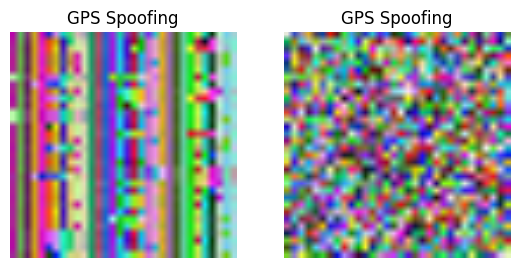

In [89]:
class_names_s = ['Benign', 'GPS Spoofing']
all_predictions_VGG19 = []
all_labels_VGG19 = []

for image_batch, label_batch in val_ds.as_numpy_iterator():
    predictions = model_VGG19.predict_on_batch(image_batch).flatten()
    predictions = tf.nn.sigmoid(predictions)
    predictions = tf.where(predictions < 0.5, 0, 1)
    all_predictions_VGG19.append(predictions)
    all_labels_VGG19.append(label_batch)
    
all_predictions_VGG19 = np.concatenate(all_predictions_VGG19)
all_labels_VGG19 = np.concatenate(all_labels_VGG19)
print('Predictions:\n', all_predictions_VGG19)
print('Labels:\n', all_labels_VGG19)
report_VGG19 = classification_report(all_labels_VGG19 , all_predictions_VGG19, target_names=class_names_s)

plt.figure(figsize=(10, 10))
for i in range(2):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(image_batch[i].astype("uint8"))
    plt.title(class_names_s[all_predictions_VGG19[i]])
    plt.axis("off")

val_ds (VGG19)
                  
              precision    recall  f1-score   support

      Benign       0.98      1.00      0.99       883
GPS Spoofing       1.00      0.97      0.99       717

    accuracy                           0.99      1600
   macro avg       0.99      0.99      0.99      1600
weighted avg       0.99      0.99      0.99      1600

                  
1) Accuracy: 0.986875
                  
2) Precision: 0.9871212908754186
                  
3) Recall: 0.986875
                  
4) Average F1-score: 0.9868567345666182
                  
5) F1-score for each type of attack: [0.98823529 0.98515901]
                  
6) Average ROC AUC: 0.9854867471896714
                  
7) Average PR AUC: 0.9832132952088654
                  
8) Balanced Accuracy: 0.9854867471896713
                  
9) Hinge: 0.565
                  
10) Matthews Correlation Coefficient: 0.9736801677661526
                  
11) Jaccard Score: 0.9707520891364902
                  
12) Lo

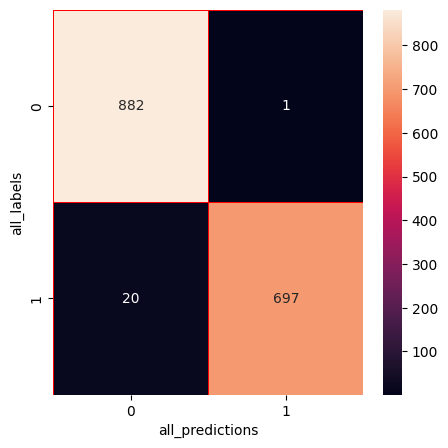

In [90]:
print("val_ds (VGG19)")
print("                  ")
print(report_VGG19)
print("                  ")

print("1) Accuracy: "+ str(accuracy_score(all_labels_VGG19 , all_predictions_VGG19)))
print("                  ")
print("2) Precision: "+ str(precision_score(all_labels_VGG19 , all_predictions_VGG19, average='weighted')))
print("                  ")
print("3) Recall: "+ str(recall_score(all_labels_VGG19 , all_predictions_VGG19, average='weighted')))
print("                  ")
print("4) Average F1-score: "+ str(f1_score(all_labels_VGG19 , all_predictions_VGG19, average='weighted')))
print("                  ")
print("5) F1-score for each type of attack: "+ str(f1_score(all_labels_VGG19 , all_predictions_VGG19, average=None)))
print("                  ")
print("6) Average ROC AUC: " + str(roc_auc_score(all_labels_VGG19, all_predictions_VGG19, average='weighted')))
print("                  ")
print("7) Average PR AUC: " + str(average_precision_score(all_labels_VGG19, all_predictions_VGG19, average='weighted')))
print("                  ")
print("8) Balanced Accuracy: "+ str(balanced_accuracy_score(all_labels_VGG19, all_predictions_VGG19)))
print("                  ")
print("9) Hinge: "+ str(hinge_loss(all_labels_VGG19, all_predictions_VGG19)))
print("                  ")
print("10) Matthews Correlation Coefficient: "+ str(matthews_corrcoef(all_labels_VGG19, all_predictions_VGG19)))
print("                  ")
print("11) Jaccard Score: "+ str(jaccard_score(all_labels_VGG19, all_predictions_VGG19)))
print("                  ")
print("12) Log Loss: "+ str(log_loss(all_labels_VGG19, all_predictions_VGG19)))
print("                  ")
print("13) Zero-One Loss "+ str(zero_one_loss(all_labels_VGG19, all_predictions_VGG19)))
print("  ")
print("14) Prediction Overhead : {:.4f}".format(prediction_overhead))
print("                  ")
print("15) Specificity: : {:.4f}".format(specificity))

cm=confusion_matrix(all_labels_VGG19 ,all_predictions_VGG19)
f,ax=plt.subplots(figsize=(5,5))
sns.heatmap(cm,annot=True,linewidth=0.5,linecolor="red",fmt=".0f",ax=ax)
plt.xlabel("all_predictions")
plt.ylabel("all_labels")
plt.show()

In [91]:
loss_val_VGG19, accuracy_val_VGG19 = model_VGG19.evaluate(val_ds)
print("Validation loss_VGG19: {:.4f}".format(loss_val_VGG19))
print("Validation accuracy_VGG19: {:.4f}".format(accuracy_val_VGG19))

50/50 [==============================] - 2s 47ms/step - loss: 0.0723 - accuracy: 0.9869
Validation loss_VGG19: 0.0723
Validation accuracy_VGG19: 0.9869


## ResNet152

In [92]:
model_ResNet152 = tf.keras.models.load_model('ResNet152+TL.h5')

Predictions:
 [1 0 1 ... 1 1 1]
Labels:
 [0 0 0 ... 0 1 1]


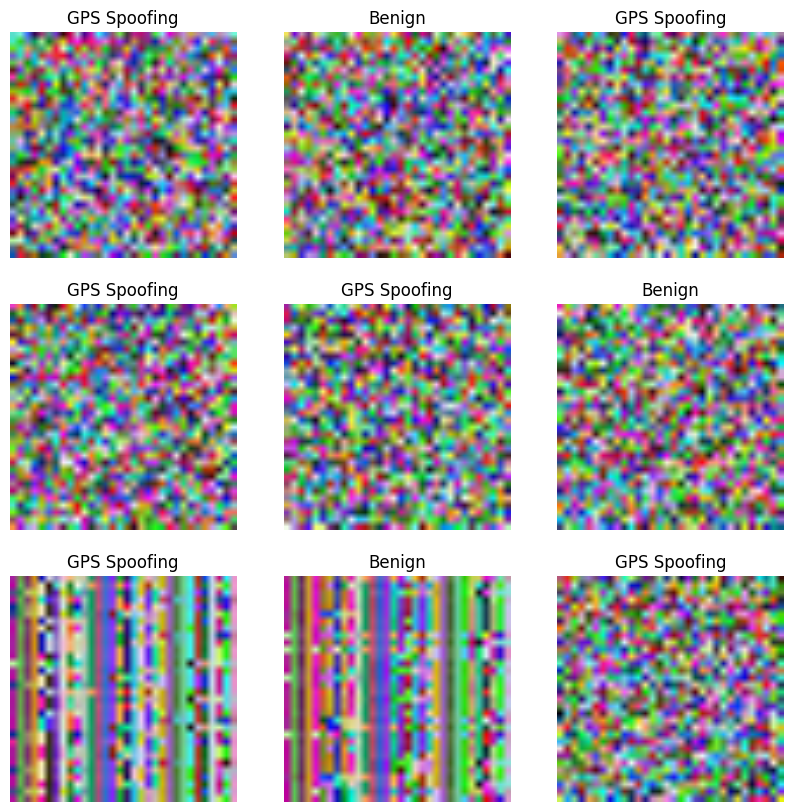

In [93]:
class_names_s = ['Benign', 'GPS Spoofing']
all_predictions_ResNet152 = []
all_labels_ResNet152 = []

for image_batch, label_batch in test_ds.as_numpy_iterator():
    predictions = model_ResNet152.predict_on_batch(image_batch).flatten()
    predictions = tf.nn.sigmoid(predictions)
    predictions = tf.where(predictions < 0.5, 0, 1)
    all_predictions_ResNet152.append(predictions)
    all_labels_ResNet152.append(label_batch)

all_predictions_ResNet152 = np.concatenate(all_predictions_ResNet152)
all_labels_ResNet152 = np.concatenate(all_labels_ResNet152)
print('Predictions:\n', all_predictions_ResNet152)
print('Labels:\n', all_labels_ResNet152)

report_ResNet152 = classification_report(all_labels_ResNet152, all_predictions_ResNet152, target_names=class_names_s)
plt.figure(figsize=(10, 10))
for i in range(9):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(image_batch[i].astype("uint8"))
    plt.title(class_names_s[all_predictions_ResNet152[i]])
    plt.axis("off")

In [94]:
cm=confusion_matrix(all_labels_ResNet152 ,all_predictions_ResNet152)
TP = np.sum((all_predictions_ResNet152 == 1) & (all_labels_ResNet152 == 1))
FP = np.sum((all_predictions_ResNet152 == 1) & (all_labels_ResNet152 == 0))
FN = np.sum((all_predictions_ResNet152 == 0) & (all_labels_ResNet152 == 1))
TN = cm[0, 0]
DA = (TP + TN) / len(all_labels_ResNet152)
DP = TP / (TP + FP)
DS = TP / (TP + FN)
DF = 2 * (DP * DS) / (DP + DS)
DE = 1 - DA
FR = FP / (FP + TN)
total_predictions = TP + FP + TN + FN
prediction_overhead = (TP + FP) / total_predictions
TN, FP, FN, TP = confusion_matrix(all_labels_ResNet152, all_predictions_ResNet152).ravel()
specificity = TN / (TN + FP)

test_ds (ResNet152)
                  
              precision    recall  f1-score   support

      Benign       0.99      0.86      0.92       889
GPS Spoofing       0.85      0.99      0.91       711

    accuracy                           0.92      1600
   macro avg       0.92      0.92      0.92      1600
weighted avg       0.93      0.92      0.92      1600

                  
1) Accuracy: 0.9175
                  
2) Precision: 0.9279507407390024
                  
3) Recall: 0.9175
                  
4) Average F1-score: 0.9177284853700516
                  
5) F1-score for each type of attack: [0.92048193 0.91428571]
                  
6) Average ROC AUC: 0.924773643800854
                  
7) Average PR AUC: 0.845230147187315
                  
8) Balanced Accuracy: 0.924773643800854
                  
9) Hinge: 0.638125
                  
10) Matthews Correlation Coefficient: 0.8448289434594051
                  
11) Jaccard Score: 0.8421052631578947
                  
12) L

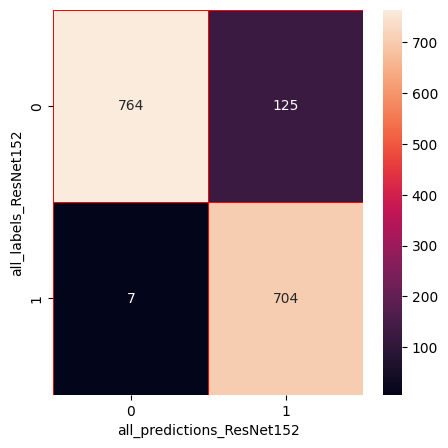

In [95]:
print("test_ds (ResNet152)")
print("                  ")
print(report_ResNet152)
print("                  ")

print("1) Accuracy: "+ str(accuracy_score(all_labels_ResNet152 , all_predictions_ResNet152)))
print("                  ")
print("2) Precision: "+ str(precision_score(all_labels_ResNet152 , all_predictions_ResNet152, average='weighted')))
print("                  ")
print("3) Recall: "+ str(recall_score(all_labels_ResNet152 , all_predictions_ResNet152, average='weighted')))
print("                  ")
print("4) Average F1-score: "+ str(f1_score(all_labels_ResNet152 , all_predictions_ResNet152, average='weighted')))
print("                  ")
print("5) F1-score for each type of attack: "+ str(f1_score(all_labels_ResNet152 , all_predictions_ResNet152, average=None)))
print("                  ")
print("6) Average ROC AUC: " + str(roc_auc_score(all_labels_ResNet152, all_predictions_ResNet152, average='weighted')))
print("                  ")
print("7) Average PR AUC: " + str(average_precision_score(all_labels_ResNet152, all_predictions_ResNet152, average='weighted')))
print("                  ")
print("8) Balanced Accuracy: "+ str(balanced_accuracy_score(all_labels_ResNet152, all_predictions_ResNet152)))
print("                  ")
print("9) Hinge: "+ str(hinge_loss(all_labels_ResNet152, all_predictions_ResNet152)))
print("                  ")
print("10) Matthews Correlation Coefficient: "+ str(matthews_corrcoef(all_labels_ResNet152, all_predictions_ResNet152)))
print("                  ")
print("11) Jaccard Score: "+ str(jaccard_score(all_labels_ResNet152, all_predictions_ResNet152)))
print("                  ")
print("12) Log Loss: "+ str(log_loss(all_labels_ResNet152, all_predictions_ResNet152)))
print("                  ")
print("13) Zero-One Loss "+ str(zero_one_loss(all_labels_ResNet152, all_predictions_ResNet152)))
print("                  ")
print("14) Prediction Overhead : {:.4f}".format(prediction_overhead))
print("                  ")
print("15) Specificity: : {:.4f}".format(specificity))

cm=confusion_matrix(all_labels_ResNet152 ,all_predictions_ResNet152)
f,ax=plt.subplots(figsize=(5,5))
sns.heatmap(cm,annot=True,linewidth=0.5,linecolor="red",fmt=".0f",ax=ax)
plt.xlabel("all_predictions_ResNet152")
plt.ylabel("all_labels_ResNet152")
plt.show()

In [96]:
loss_test_ResNet152, accuracy_test_ResNet152 = model_ResNet152.evaluate(test_ds)
print("Test Loss: {:.4f}".format(loss_test_ResNet152))
print("Test Accuracy: {:.4f}".format(accuracy_test_ResNet152))

50/50 [==============================] - 6s 80ms/step - loss: 0.1878 - accuracy: 0.9425
Test Loss: 0.1878
Test Accuracy: 0.9425


### VAL_ds (ResNet152)

Predictions:
 [1 0 0 ... 0 1 1]
Labels:
 [1 0 0 ... 0 0 1]


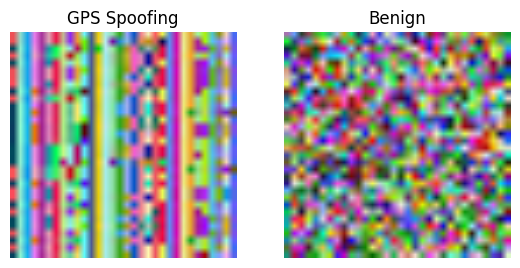

In [97]:
class_names_s = ['Benign', 'GPS Spoofing']
all_predictions_ResNet152 = []
all_labels_ResNet152 = []

for image_batch, label_batch in val_ds.as_numpy_iterator():
    predictions = model_ResNet152.predict_on_batch(image_batch).flatten()
    predictions = tf.nn.sigmoid(predictions)
    predictions = tf.where(predictions < 0.5, 0, 1)
    all_predictions_ResNet152.append(predictions)
    all_labels_ResNet152.append(label_batch)

all_predictions_ResNet152 = np.concatenate(all_predictions_ResNet152)
all_labels_ResNet152 = np.concatenate(all_labels_ResNet152)
print('Predictions:\n', all_predictions_ResNet152)
print('Labels:\n', all_labels_ResNet152)

report_ResNet152 = classification_report(all_labels_ResNet152 , all_predictions_ResNet152, target_names=class_names_s)
plt.figure(figsize=(10, 10))
for i in range(2):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(image_batch[i].astype("uint8"))
    plt.title(class_names_s[all_predictions_ResNet152[i]])
    plt.axis("off")

val_ds (ResNet152)
                  
              precision    recall  f1-score   support

      Benign       0.98      0.88      0.93       869
GPS Spoofing       0.87      0.98      0.92       731

    accuracy                           0.93      1600
   macro avg       0.93      0.93      0.92      1600
weighted avg       0.93      0.93      0.93      1600

                  
1) Accuracy: 0.925
                  
2) Precision: 0.931904114217601
                  
3) Recall: 0.925
                  
4) Average F1-score: 0.9251182064516331
                  
5) F1-score for each type of attack: [0.92691839 0.92297818]
                  
6) Average ROC AUC: 0.9296516744091594
                  
7) Average PR AUC: 0.8626354176832849
                  
8) Balanced Accuracy: 0.9296516744091594
                  
9) Hinge: 0.618125
                  
10) Matthews Correlation Coefficient: 0.8565891700568676
                  
11) Jaccard Score: 0.8569725864123957
                  
12) Lo

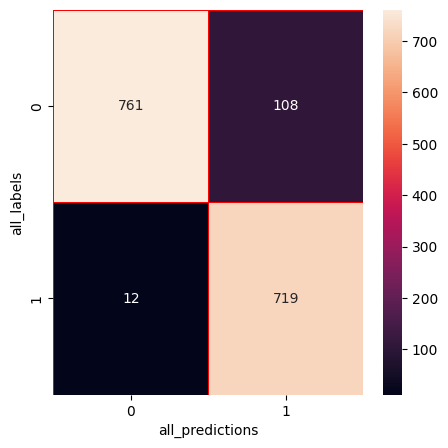

In [98]:
print("val_ds (ResNet152)")
print("                  ")
print(report_ResNet152)
print("                  ")

print("1) Accuracy: "+ str(accuracy_score(all_labels_ResNet152, all_predictions_ResNet152)))
print("                  ")
print("2) Precision: "+ str(precision_score(all_labels_ResNet152, all_predictions_ResNet152, average='weighted')))
print("                  ")
print("3) Recall: "+ str(recall_score(all_labels_ResNet152, all_predictions_ResNet152, average='weighted')))
print("                  ")
print("4) Average F1-score: "+ str(f1_score(all_labels_ResNet152, all_predictions_ResNet152, average='weighted')))
print("                  ")
print("5) F1-score for each type of attack: "+ str(f1_score(all_labels_ResNet152, all_predictions_ResNet152, average=None)))
print("                  ")
print("6) Average ROC AUC: " + str(roc_auc_score(all_labels_ResNet152, all_predictions_ResNet152, average='weighted')))
print("                  ")
print("7) Average PR AUC: " + str(average_precision_score(all_labels_ResNet152, all_predictions_ResNet152, average='weighted')))
print("                  ")
print("8) Balanced Accuracy: "+ str(balanced_accuracy_score(all_labels_ResNet152, all_predictions_ResNet152)))
print("                  ")
print("9) Hinge: "+ str(hinge_loss(all_labels_ResNet152, all_predictions_ResNet152)))
print("                  ")
print("10) Matthews Correlation Coefficient: "+ str(matthews_corrcoef(all_labels_ResNet152, all_predictions_ResNet152)))
print("                  ")
print("11) Jaccard Score: "+ str(jaccard_score(all_labels_ResNet152, all_predictions_ResNet152)))
print("                  ")
print("12) Log Loss: "+ str(log_loss(all_labels_ResNet152, all_predictions_ResNet152)))
print("                  ")
print("13) Zero-One Loss "+ str(zero_one_loss(all_labels_ResNet152, all_predictions_ResNet152)))
print("                  ")
print("14) Prediction Overhead : {:.4f}".format(prediction_overhead))
print("                  ")
print("15) Specificity: : {:.4f}".format(specificity))

cm=confusion_matrix(all_labels_ResNet152 ,all_predictions_ResNet152)
f,ax=plt.subplots(figsize=(5,5))
sns.heatmap(cm,annot=True,linewidth=0.5,linecolor="red",fmt=".0f",ax=ax)
plt.xlabel("all_predictions")
plt.ylabel("all_labels")
plt.show()

In [99]:
loss_val_ResNet152, accuracy_val_ResNet152 = model_ResNet152.evaluate(val_ds)
print("Validation Loss: {:.4f}".format(loss_val_ResNet152))
print("Validation Accuracy: {:.4f}".format(accuracy_val_ResNet152))

50/50 [==============================] - 4s 80ms/step - loss: 0.1864 - accuracy: 0.9444
Validation Loss: 0.1864
Validation Accuracy: 0.9444


## InceptionV3 

In [18]:
model_InceptionV3 = tf.keras.models.load_model('InceptionV3+TL.h5')

Predictions:
 [0 0 0 ... 0 0 0]
Labels:
 [1 1 1 ... 1 1 0]


/usr/local/lib64/python3.9/site-packages/sklearn/metrics/_classification.py:1471: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib64/python3.9/site-packages/sklearn/metrics/_classification.py:1471: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib64/python3.9/site-packages/sklearn/metrics/_classification.py:1471: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


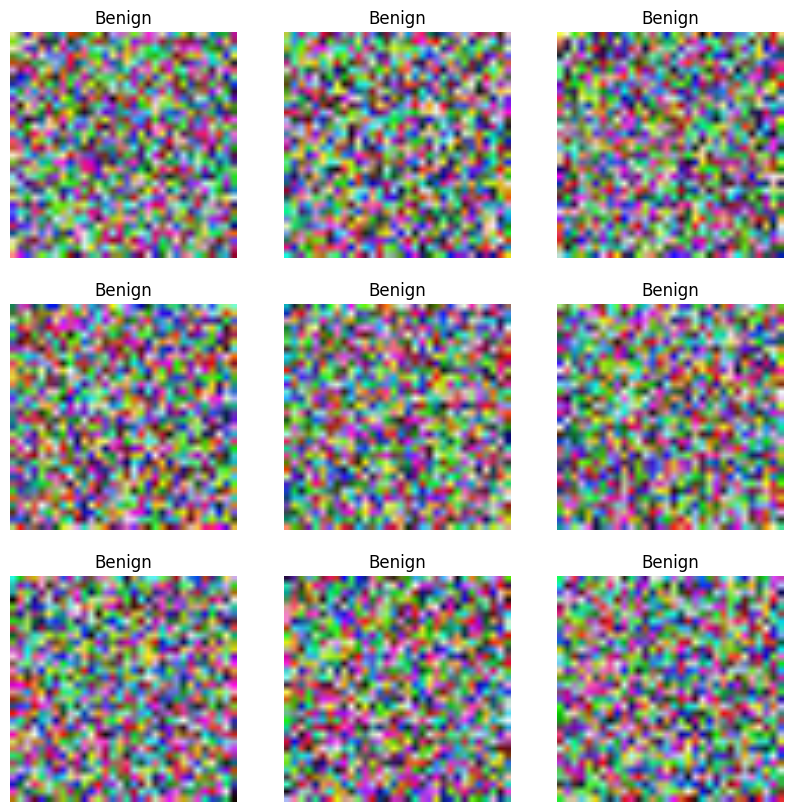

In [20]:
class_names_s = ['Benign', 'GPS Spoofing']
all_predictions_InceptionV3 = []
all_labels_InceptionV3 = []

for image_batch, label_batch in test_ds.as_numpy_iterator():
    predictions = model_InceptionV3.predict_on_batch(image_batch).flatten()
    predictions = tf.nn.sigmoid(predictions)
    predictions = tf.where(predictions < 0.5, 0, 1)
    all_predictions_InceptionV3.append(predictions)
    all_labels_InceptionV3.append(label_batch)

all_predictions_InceptionV3 = np.concatenate(all_predictions_InceptionV3)
all_labels_InceptionV3 = np.concatenate(all_labels_InceptionV3)
print('Predictions:\n', all_predictions_InceptionV3)
print('Labels:\n', all_labels_InceptionV3)

report_InceptionV3 = classification_report(all_labels_InceptionV3, all_predictions_InceptionV3, target_names=class_names_s)
plt.figure(figsize=(10, 10))
for i in range(9):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(image_batch[i].astype("uint8"))
    plt.title(class_names_s[all_predictions_InceptionV3[i]])
    plt.axis("off")

In [21]:
cm=confusion_matrix(all_labels_InceptionV3 ,all_predictions_InceptionV3)
TP = np.sum((all_predictions_InceptionV3 == 1) & (all_labels_InceptionV3 == 1))
FP = np.sum((all_predictions_InceptionV3 == 1) & (all_labels_InceptionV3 == 0))
FN = np.sum((all_predictions_InceptionV3 == 0) & (all_labels_InceptionV3 == 1))
TN = cm[0, 0]
DA = (TP + TN) / len(all_labels_InceptionV3)
DP = TP / (TP + FP)
DS = TP / (TP + FN)
DF = 2 * (DP * DS) / (DP + DS)
DE = 1 - DA
FR = FP / (FP + TN)
total_predictions = TP + FP + TN + FN
prediction_overhead = (TP + FP) / total_predictions
TN, FP, FN, TP = confusion_matrix(all_labels_InceptionV3, all_predictions_InceptionV3).ravel()
specificity = TN / (TN + FP)

/run/nvme/job_20373119/tmp/ipykernel_2344646/2033614532.py:7: RuntimeWarning: invalid value encountered in scalar divide
  DP = TP / (TP + FP)


test_ds (InceptionV3)
                  
1) Accuracy: 0.471875
                  
2) Precision: 0.222666015625
                  
3) Recall: 0.471875
                  
4) Average F1-score: 0.30256104033970277
                  
5) F1-score for each type of attack: [0.64118896 0.        ]
                  
6) Average ROC AUC: 0.5
                  
7) Average PR AUC: 0.528125
                  
8) Balanced Accuracy: 0.5
                  
9) Hinge: 1.0
                  
10) Matthews Correlation Coefficient: 0.0
                  
11) Jaccard Score: 0.0
                  
12) Log Loss: 19.035554446127495
                  
13) Zero-One Loss 0.528125
                  
14) Prediction Overhead : 0.0000
                  
15) Specificity: : 1.0000


/usr/local/lib64/python3.9/site-packages/sklearn/metrics/_classification.py:1471: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


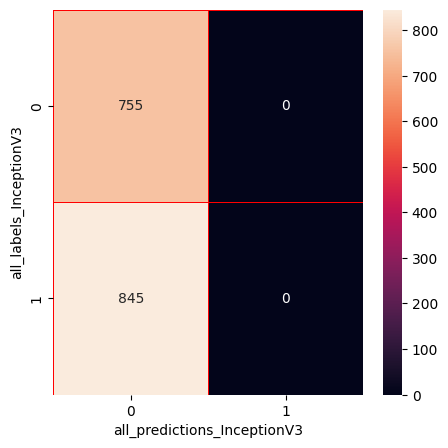

In [26]:
print("test_ds (InceptionV3)")
print("                  ")
print("1) Accuracy: "+ str(accuracy_score(all_labels_InceptionV3 , all_predictions_InceptionV3)))
print("                  ")
print("2) Precision: "+ str(precision_score(all_labels_InceptionV3 , all_predictions_InceptionV3, average='weighted')))
print("                  ")
print("3) Recall: "+ str(recall_score(all_labels_InceptionV3 , all_predictions_InceptionV3, average='weighted')))
print("                  ")
print("4) Average F1-score: "+ str(f1_score(all_labels_InceptionV3 , all_predictions_InceptionV3, average='weighted')))
print("                  ")
print("5) F1-score for each type of attack: "+ str(f1_score(all_labels_InceptionV3 , all_predictions_InceptionV3, average=None)))
print("                  ")
print("6) Average ROC AUC: " + str(roc_auc_score(all_labels_InceptionV3, all_predictions_InceptionV3, average='weighted')))
print("                  ")
print("7) Average PR AUC: " + str(average_precision_score(all_labels_InceptionV3, all_predictions_InceptionV3, average='weighted')))
print("                  ")
print("8) Balanced Accuracy: "+ str(balanced_accuracy_score(all_labels_InceptionV3, all_predictions_InceptionV3)))
print("                  ")
print("9) Hinge: "+ str(hinge_loss(all_labels_InceptionV3, all_predictions_InceptionV3)))
print("                  ")
print("10) Matthews Correlation Coefficient: "+ str(matthews_corrcoef(all_labels_InceptionV3, all_predictions_InceptionV3)))
print("                  ")
print("11) Jaccard Score: "+ str(jaccard_score(all_labels_InceptionV3, all_predictions_InceptionV3)))
print("                  ")
print("12) Log Loss: "+ str(log_loss(all_labels_InceptionV3, all_predictions_InceptionV3)))
print("                  ")
print("13) Zero-One Loss "+ str(zero_one_loss(all_labels_InceptionV3, all_predictions_InceptionV3)))
print("                  ")
print("14) Prediction Overhead : {:.4f}".format(prediction_overhead))
print("                  ")
print("15) Specificity: : {:.4f}".format(specificity))

cm=confusion_matrix(all_labels_InceptionV3 ,all_predictions_InceptionV3)
f,ax=plt.subplots(figsize=(5,5))
sns.heatmap(cm,annot=True,linewidth=0.5,linecolor="red",fmt=".0f",ax=ax)
plt.xlabel("all_predictions_InceptionV3")
plt.ylabel("all_labels_InceptionV3")
plt.show()

In [27]:
loss_test_InceptionV3, accuracy_test_InceptionV3 = model_InceptionV3.evaluate(test_ds)
print("Test loss: {:.4f}".format(loss_test_InceptionV3))
print("Test accuracy: {:.4f}".format(accuracy_test_InceptionV3))

50/50 [==============================] - 2s 31ms/step - loss: 4.0102 - accuracy: 0.4538
Test loss: 4.0102
Test accuracy: 0.4538


Predictions:
 [0 0 0 ... 0 0 0]
Labels:
 [1 0 0 ... 1 1 0]


/usr/local/lib64/python3.9/site-packages/sklearn/metrics/_classification.py:1471: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib64/python3.9/site-packages/sklearn/metrics/_classification.py:1471: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib64/python3.9/site-packages/sklearn/metrics/_classification.py:1471: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


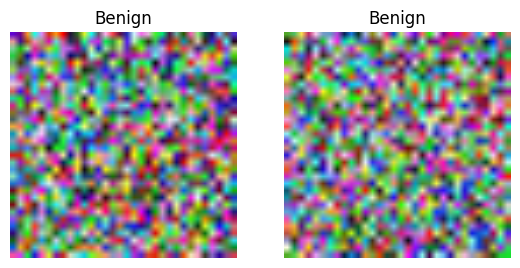

In [28]:
class_names_s = ['Benign', 'GPS Spoofing']
all_predictions_InceptionV3 = []
all_labels_InceptionV3 = []

for image_batch, label_batch in val_ds.as_numpy_iterator():
    predictions = model_InceptionV3.predict_on_batch(image_batch).flatten()
    predictions = tf.nn.sigmoid(predictions)
    predictions = tf.where(predictions < 0.5, 0, 1)
    all_predictions_InceptionV3.append(predictions)
    all_labels_InceptionV3.append(label_batch)

all_predictions_InceptionV3 = np.concatenate(all_predictions_InceptionV3)
all_labels_InceptionV3 = np.concatenate(all_labels_InceptionV3)
print('Predictions:\n', all_predictions_InceptionV3)
print('Labels:\n', all_labels_InceptionV3)

report_InceptionV3 = classification_report(all_labels_InceptionV3, all_predictions_InceptionV3, target_names=class_names_s)

plt.figure(figsize=(10, 10))
for i in range(2):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(image_batch[i].astype("uint8"))
    plt.title(class_names_s[all_predictions_InceptionV3[i]])
    plt.axis("off")

val_ds (InceptionV3)
                  
              precision    recall  f1-score   support

      Benign       0.47      1.00      0.64       746
GPS Spoofing       0.00      0.00      0.00       854

    accuracy                           0.47      1600
   macro avg       0.23      0.50      0.32      1600
weighted avg       0.22      0.47      0.30      1600

                  
1) Accuracy: 0.46625
                  
2) Precision: 0.2173890625
                  
3) Recall: 0.46625
                  
4) Average F1-score: 0.2965238704177323
                  
5) F1-score for each type of attack: [0.63597613 0.        ]
                  
6) Average ROC AUC: 0.5
                  
7) Average PR AUC: 0.53375
                  
8) Balanced Accuracy: 0.5
                  
9) Hinge: 1.0
                  
10) Matthews Correlation Coefficient: 0.0
                  
11) Jaccard Score: 0.0
                  
12) Log Loss: 19.238299996441278
                  
13) Zero-One Loss 0.53375
   

/usr/local/lib64/python3.9/site-packages/sklearn/metrics/_classification.py:1471: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


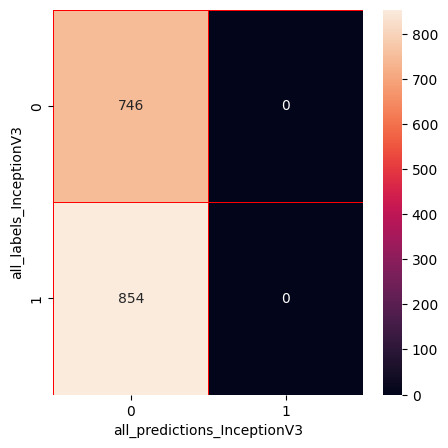

In [29]:
print("val_ds (InceptionV3)")
print("                  ")
print(report_InceptionV3)
print("                  ")

print("1) Accuracy: "+ str(accuracy_score(all_labels_InceptionV3 , all_predictions_InceptionV3)))
print("                  ")
print("2) Precision: "+ str(precision_score(all_labels_InceptionV3 , all_predictions_InceptionV3, average='weighted')))
print("                  ")
print("3) Recall: "+ str(recall_score(all_labels_InceptionV3 , all_predictions_InceptionV3, average='weighted')))
print("                  ")
print("4) Average F1-score: "+ str(f1_score(all_labels_InceptionV3 , all_predictions_InceptionV3, average='weighted')))
print("                  ")
print("5) F1-score for each type of attack: "+ str(f1_score(all_labels_InceptionV3 , all_predictions_InceptionV3, average=None)))
print("                  ")
print("6) Average ROC AUC: " + str(roc_auc_score(all_labels_InceptionV3, all_predictions_InceptionV3, average='weighted')))
print("                  ")
print("7) Average PR AUC: " + str(average_precision_score(all_labels_InceptionV3, all_predictions_InceptionV3, average='weighted')))
print("                  ")
print("8) Balanced Accuracy: "+ str(balanced_accuracy_score(all_labels_InceptionV3, all_predictions_InceptionV3)))
print("                  ")
print("9) Hinge: "+ str(hinge_loss(all_labels_InceptionV3, all_predictions_InceptionV3)))
print("                  ")
print("10) Matthews Correlation Coefficient: "+ str(matthews_corrcoef(all_labels_InceptionV3, all_predictions_InceptionV3)))
print("                  ")
print("11) Jaccard Score: "+ str(jaccard_score(all_labels_InceptionV3, all_predictions_InceptionV3)))
print("                  ")
print("12) Log Loss: "+ str(log_loss(all_labels_InceptionV3, all_predictions_InceptionV3)))
print("                  ")
print("13) Zero-One Loss "+ str(zero_one_loss(all_labels_InceptionV3, all_predictions_InceptionV3)))
print("                  ")
print("14) Prediction Overhead : {:.4f}".format(prediction_overhead))
print("                  ")
print("15) Specificity: : {:.4f}".format(specificity))

cm=confusion_matrix(all_labels_InceptionV3 ,all_predictions_InceptionV3)
f,ax=plt.subplots(figsize=(5,5))
sns.heatmap(cm,annot=True,linewidth=0.5,linecolor="red",fmt=".0f",ax=ax)
plt.xlabel("all_predictions_InceptionV3")
plt.ylabel("all_labels_InceptionV3")
plt.show()

## InceptionV3 + Bayesian optimization 

In [107]:
model_InceptionV3 = tf.keras.models.load_model('InceptionV3+TL.h5')

Predictions:
 [1 0 0 ... 0 0 1]
Labels:
 [1 0 0 ... 0 0 1]


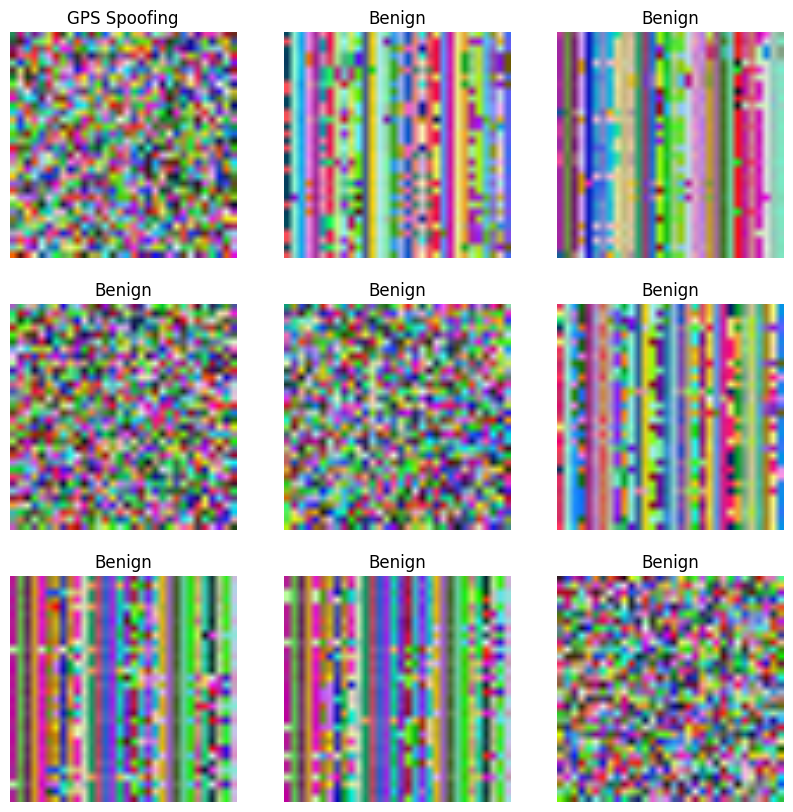

In [108]:
all_predictions_InceptionV3 = []
all_labels_InceptionV3 = []

for image_batch, label_batch in test_ds.as_numpy_iterator():
    predictions = model_InceptionV3.predict_on_batch(image_batch).flatten()
    predictions = tf.nn.sigmoid(predictions)
    predictions = tf.where(predictions < 0.5, 0, 1)
    all_predictions_InceptionV3.append(predictions)
    all_labels_InceptionV3.append(label_batch)

all_predictions_InceptionV3 = np.concatenate(all_predictions_InceptionV3)
all_labels_InceptionV3 = np.concatenate(all_labels_InceptionV3)
print('Predictions:\n', all_predictions_InceptionV3)
print('Labels:\n', all_labels_InceptionV3)

report_InceptionV3 = classification_report(all_labels_InceptionV3, all_predictions_InceptionV3, target_names=class_names_s)
plt.figure(figsize=(10, 10))
for i in range(9):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(image_batch[i].astype("uint8"))
    plt.title(class_names_s[all_predictions_InceptionV3[i]])
    plt.axis("off")

In [109]:
cm=confusion_matrix(all_labels_InceptionV3 ,all_predictions_InceptionV3)
TP = np.sum((all_predictions_InceptionV3 == 1) & (all_labels_InceptionV3 == 1))
FP = np.sum((all_predictions_InceptionV3 == 1) & (all_labels_InceptionV3 == 0))
FN = np.sum((all_predictions_InceptionV3 == 0) & (all_labels_InceptionV3 == 1))
TN = cm[0, 0]
DA = (TP + TN) / len(all_labels_InceptionV3)
DP = TP / (TP + FP)
DS = TP / (TP + FN)
DF = 2 * (DP * DS) / (DP + DS)
DE = 1 - DA
FR = FP / (FP + TN)
total_predictions = TP + FP + TN + FN
prediction_overhead = (TP + FP) / total_predictions
TN, FP, FN, TP = confusion_matrix(all_labels_InceptionV3, all_predictions_InceptionV3).ravel()
specificity = TN / (TN + FP)

test_ds (InceptionV3)
                  
              precision    recall  f1-score   support

      Benign       0.98      1.00      0.99       894
GPS Spoofing       1.00      0.98      0.99       706

    accuracy                           0.99      1600
   macro avg       0.99      0.99      0.99      1600
weighted avg       0.99      0.99      0.99      1600

                  
1) Accuracy: 0.990625
                  
2) Precision: 0.990779702970297
                  
3) Recall: 0.990625
                  
4) Average F1-score: 0.9906136664375884
                  
5) F1-score for each type of attack: [0.99168053 0.98926271]
                  
6) Average ROC AUC: 0.9893767705382437
                  
7) Average PR AUC: 0.9881285410764873
                  
8) Balanced Accuracy: 0.9893767705382437
                  
9) Hinge: 0.568125
                  
10) Matthews Correlation Coefficient: 0.981123077164059
                  
11) Jaccard Score: 0.9787535410764873
                 

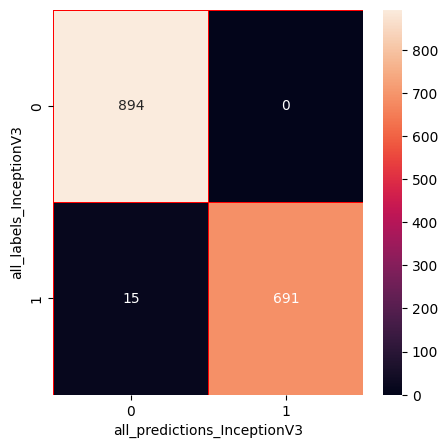

In [110]:
print("test_ds (InceptionV3)")
print("                  ")
print(report_InceptionV3)
print("                  ")

print("1) Accuracy: "+ str(accuracy_score(all_labels_InceptionV3 , all_predictions_InceptionV3)))
print("                  ")
print("2) Precision: "+ str(precision_score(all_labels_InceptionV3 , all_predictions_InceptionV3, average='weighted')))
print("                  ")
print("3) Recall: "+ str(recall_score(all_labels_InceptionV3 , all_predictions_InceptionV3, average='weighted')))
print("                  ")
print("4) Average F1-score: "+ str(f1_score(all_labels_InceptionV3 , all_predictions_InceptionV3, average='weighted')))
print("                  ")
print("5) F1-score for each type of attack: "+ str(f1_score(all_labels_InceptionV3 , all_predictions_InceptionV3, average=None)))
print("                  ")
print("6) Average ROC AUC: " + str(roc_auc_score(all_labels_InceptionV3, all_predictions_InceptionV3, average='weighted')))
print("                  ")
print("7) Average PR AUC: " + str(average_precision_score(all_labels_InceptionV3, all_predictions_InceptionV3, average='weighted')))
print("                  ")
print("8) Balanced Accuracy: "+ str(balanced_accuracy_score(all_labels_InceptionV3, all_predictions_InceptionV3)))
print("                  ")
print("9) Hinge: "+ str(hinge_loss(all_labels_InceptionV3, all_predictions_InceptionV3)))
print("                  ")
print("10) Matthews Correlation Coefficient: "+ str(matthews_corrcoef(all_labels_InceptionV3, all_predictions_InceptionV3)))
print("                  ")
print("11) Jaccard Score: "+ str(jaccard_score(all_labels_InceptionV3, all_predictions_InceptionV3)))
print("                  ")
print("12) Log Loss: "+ str(log_loss(all_labels_InceptionV3, all_predictions_InceptionV3)))
print("                  ")
print("13) Zero-One Loss "+ str(zero_one_loss(all_labels_InceptionV3, all_predictions_InceptionV3)))
print("                  ")
print("14) Prediction Overhead : {:.4f}".format(prediction_overhead))
print("                  ")
print("15) Specificity: : {:.4f}".format(specificity))

cm=confusion_matrix(all_labels_InceptionV3 ,all_predictions_InceptionV3)
f,ax=plt.subplots(figsize=(5,5))
sns.heatmap(cm,annot=True,linewidth=0.5,linecolor="red",fmt=".0f",ax=ax)
plt.xlabel("all_predictions_InceptionV3")
plt.ylabel("all_labels_InceptionV3")
plt.show()

In [111]:
loss_test_InceptionV3, accuracy_test_InceptionV3 = model_InceptionV3.evaluate(test_ds)
print("Test loss: {:.4f}".format(loss_test_InceptionV3))
print("Test accuracy: {:.4f}".format(accuracy_test_InceptionV3))

50/50 [==============================] - 3s 30ms/step - loss: 0.0547 - accuracy: 0.9919
Test loss: 0.0547
Test accuracy: 0.9919


### val InceptionV3

Predictions:
 [1 1 0 ... 1 0 1]
Labels:
 [1 1 0 ... 1 0 1]


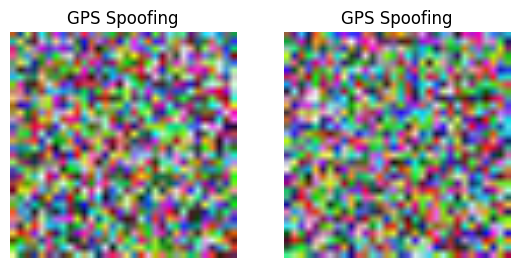

In [17]:
class_names_s = ['Benign', 'GPS Spoofing']
all_predictions_InceptionV3 = []
all_labels_InceptionV3 = []

for image_batch, label_batch in val_ds.as_numpy_iterator():
    predictions = model_InceptionV3.predict_on_batch(image_batch).flatten()
    predictions = tf.nn.sigmoid(predictions)
    predictions = tf.where(predictions < 0.5, 0, 1)
    all_predictions_InceptionV3.append(predictions)
    all_labels_InceptionV3.append(label_batch)

all_predictions_InceptionV3 = np.concatenate(all_predictions_InceptionV3)
all_labels_InceptionV3 = np.concatenate(all_labels_InceptionV3)
print('Predictions:\n', all_predictions_InceptionV3)
print('Labels:\n', all_labels_InceptionV3)

report_InceptionV3 = classification_report(all_labels_InceptionV3, all_predictions_InceptionV3, target_names=class_names_s)

plt.figure(figsize=(10, 10))
for i in range(2):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(image_batch[i].astype("uint8"))
    plt.title(class_names_s[all_predictions_InceptionV3[i]])
    plt.axis("off")

val_ds (InceptionV3)
                  
              precision    recall  f1-score   support

      Benign       0.98      1.00      0.99      1006
GPS Spoofing       1.00      0.96      0.98       594

    accuracy                           0.99      1600
   macro avg       0.99      0.98      0.98      1600
weighted avg       0.99      0.99      0.99      1600

                  
1) Accuracy: 0.985625
                  
2) Precision: 0.9859463070942663
                  
3) Recall: 0.985625
                  
4) Average F1-score: 0.9855643355021038
                  
5) F1-score for each type of attack: [0.98869779 0.98025751]
                  
6) Average ROC AUC: 0.9806397306397306
                  
7) Average PR AUC: 0.9756544612794613
                  
8) Balanced Accuracy: 0.9806397306397306
                  
9) Hinge: 0.643125
                  
10) Matthews Correlation Coefficient: 0.9694292842038807
                  
11) Jaccard Score: 0.9612794612794613
                

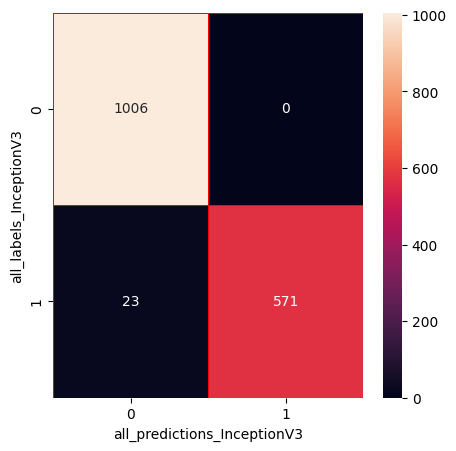

In [18]:
print("val_ds (InceptionV3)")
print("                  ")
print(report_InceptionV3)
print("                  ")

print("1) Accuracy: "+ str(accuracy_score(all_labels_InceptionV3 , all_predictions_InceptionV3)))
print("                  ")
print("2) Precision: "+ str(precision_score(all_labels_InceptionV3 , all_predictions_InceptionV3, average='weighted')))
print("                  ")
print("3) Recall: "+ str(recall_score(all_labels_InceptionV3 , all_predictions_InceptionV3, average='weighted')))
print("                  ")
print("4) Average F1-score: "+ str(f1_score(all_labels_InceptionV3 , all_predictions_InceptionV3, average='weighted')))
print("                  ")
print("5) F1-score for each type of attack: "+ str(f1_score(all_labels_InceptionV3 , all_predictions_InceptionV3, average=None)))
print("                  ")
print("6) Average ROC AUC: " + str(roc_auc_score(all_labels_InceptionV3, all_predictions_InceptionV3, average='weighted')))
print("                  ")
print("7) Average PR AUC: " + str(average_precision_score(all_labels_InceptionV3, all_predictions_InceptionV3, average='weighted')))
print("                  ")
print("8) Balanced Accuracy: "+ str(balanced_accuracy_score(all_labels_InceptionV3, all_predictions_InceptionV3)))
print("                  ")
print("9) Hinge: "+ str(hinge_loss(all_labels_InceptionV3, all_predictions_InceptionV3)))
print("                  ")
print("10) Matthews Correlation Coefficient: "+ str(matthews_corrcoef(all_labels_InceptionV3, all_predictions_InceptionV3)))
print("                  ")
print("11) Jaccard Score: "+ str(jaccard_score(all_labels_InceptionV3, all_predictions_InceptionV3)))
print("                  ")
print("12) Log Loss: "+ str(log_loss(all_labels_InceptionV3, all_predictions_InceptionV3)))
print("                  ")
print("13) Zero-One Loss "+ str(zero_one_loss(all_labels_InceptionV3, all_predictions_InceptionV3)))
print("                  ")
print("14) Prediction Overhead : {:.4f}".format(prediction_overhead))
print("                  ")
print("15) Specificity: : {:.4f}".format(specificity))

cm=confusion_matrix(all_labels_InceptionV3 ,all_predictions_InceptionV3)
f,ax=plt.subplots(figsize=(5,5))
sns.heatmap(cm,annot=True,linewidth=0.5,linecolor="red",fmt=".0f",ax=ax)
plt.xlabel("all_predictions_InceptionV3")
plt.ylabel("all_labels_InceptionV3")
plt.show()

In [19]:
loss_val_InceptionV3, accuracy_val_InceptionV3 = model_InceptionV3.evaluate(val_ds)
print("Validation Loss: {:.4f}".format(loss_val_InceptionV3))
print("Validation Accuracy: {:.4f}".format(accuracy_val_InceptionV3))

50/50 [==============================] - 2s 31ms/step - loss: 0.0879 - accuracy: 0.9869
Validation Loss: 0.0879
Validation Accuracy: 0.9869
